# [PBT] 스킨케어 만족/불만족 분류
## 제품 통제 + 국가×속성 + `my_ml` 머신러닝 파이프라인

이 버전은 **테스트셋 오염(Test-set leakage) 문제를 수정한 버전**입니다.

### 핵심 원칙

```text
Train 70%
│
├─ Train 내부 5-Fold CV
│   ├─ 베이스라인 비교
│   ├─ 하이퍼파라미터 튜닝
│   ├─ 최종 모델 선택
│   └─ Train/CV 과적합 진단
│
└─ 최종 모델 확정
        ↓
   Test 30% 단 한 번 평가
```

**테스트셋은 최종 모델이 확정되기 전까지 모델 성능 비교·튜닝·선택에 사용하지 않습니다.**

---

## 최종 X 구성

```text
제품_ID                         1개 범주형
9개 속성                        9개
국가×속성 상호작용             27개
------------------------------------
원본 기준                       37개 변수
```

`제품_ID`는 `KR_P01`, `US_P03`처럼 국가별 제품을 구분하는 **명목형 변수**이며,
기존 `제품_순위`는 머신러닝 입력에서 제거합니다.


# 00. 실행 환경

강사님이 제공한 `helpers.my_ml`의 기능을 최대한 그대로 사용합니다.

주요 사용 함수:

- `my_ml.cls_baseline()` : 11개 분류모델 베이스라인 일괄 학습
- `my_ml.load_model()` / `save_model()`
- `my_ml.cls_compare_models()` : 모델 성능 비교
- `my_ml.cls_overfit()` : 과적합 진단
- `my_ml.feature_importance()` : 변수 중요도 / 누적 중요도 기준 변수 선택
- `my_ml.shap_analysis()` : SHAP 분석
- `my_ml.shap_dependence_plot()`
- `my_ml.shap_waterfall_plot()`

`fit_pipeline()` 내부에서 `category/object`형 변수는 자동으로 명목형으로 인식합니다.

In [15]:
%pip install kneed

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
%pip install xgboost lightgbm catboost shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import os
import sys
import glob
import warnings
from pathlib import Path
import importlib

warnings.filterwarnings("ignore")

# ---------------------------------------------------------
# 사용자 환경
# ---------------------------------------------------------
HELPER_PATH = r"C:\Users\openi\OneDrive\Desktop\주영아강사님"

if HELPER_PATH not in sys.path:
    sys.path.insert(0, HELPER_PATH)

for module_name in list(sys.modules.keys()):
    if module_name == "helpers" or module_name.startswith("helpers."):
        del sys.modules[module_name]

from helpers import my_ml

try:
    from helpers import RANDOM_STATE
except Exception:
    RANDOM_STATE = 42

import numpy as np
import pandas as pd

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
)
from sklearn.linear_model import (
    LogisticRegression,
    RidgeClassifier,
    SGDClassifier,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

print("helpers 위치:", importlib.import_module("helpers").__file__)
print("my_ml 위치:", my_ml.__file__)
print("RANDOM_STATE =", RANDOM_STATE)


helpers 위치: C:\Users\openi\OneDrive\Desktop\주영아강사님\helpers\__init__.py
my_ml 위치: C:\Users\openi\OneDrive\Desktop\주영아강사님\helpers\my_ml.py
RANDOM_STATE = 3217


# 01. ml_df.xlsx 불러오기

현재 분석에 사용할 데이터 파일인 **`ml_df.xlsx`**를 불러옵니다.

파일 경로는 다음과 같습니다.

`C:\Users\openi\Downloads\ml_df.xlsx`

해당 파일의 `Sheet1` 시트를 사용하여 분석을 진행합니다.

In [18]:
from pathlib import Path

DATA_FILE = Path(r"C:\Users\openi\Downloads\ml_df.xlsx")

SHEET_NAME = "Sheet1"

print("사용 파일:", DATA_FILE)

origin = pd.read_excel(
    DATA_FILE,
    sheet_name=SHEET_NAME
)

# 컬럼명 통일
origin = origin.rename(
    columns={"브랜드 충성도": "브랜드충성도"}
)

print("Shape:", origin.shape)

display(origin.head())

사용 파일: C:\Users\openi\Downloads\ml_df.xlsx
Shape: (6756, 43)


,국가,제품_순위,Y,보습,향,발림성,자극,용기,배송,기능,...,국가_일본_x_보습,국가_일본_x_향,국가_일본_x_발림성,국가_일본_x_자극,국가_일본_x_용기,국가_일본_x_배송,국가_일본_x_기능,국가_일본_x_가격,국가_일본_x_브랜드충성도,제품_ID
0,러시아,1,1,0,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,러시아_1
1,러시아,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,러시아_1
2,러시아,1,1,1,1,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,러시아_1
3,러시아,1,1,0,1,1,0,1,1,0,...,0,0,0,0,0,0,0,0,0,러시아_1
4,러시아,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,러시아_1


## 01-1. 데이터 구조 확인

현재 `ml_df.xlsx`의 `Sheet1`에는 다음과 같은 기본 구조가 포함되어 있는지 확인합니다.

- `국가`
- `제품_순위`
- `Y`
- 9개 속성
- 국가 더미 3개
- 국가×속성 27개

또한 필수 컬럼 누락 여부, 결측치, 상호작용항 개수를 함께 점검합니다.

In [19]:
attrs = [
    "보습", "향", "발림성", "자극",
    "용기", "배송", "기능", "가격", "브랜드충성도"
]

country_dummy_cols = [
    "국가_러시아",
    "국가_미국",
    "국가_일본"
]

interaction_cols = [c for c in origin.columns if "_x_" in c]

required_cols = (
    ["국가", "제품_순위", "Y"]
    + attrs
    + country_dummy_cols
    + interaction_cols
)

missing = [c for c in required_cols if c not in origin.columns]

print("전체 행:", len(origin))
print("국가×속성 상호작용항:", len(interaction_cols))
print("필수 컬럼 누락:", missing)
print("결측치 총합:", int(origin.isna().sum().sum()))

if missing:
    raise KeyError(f"필수 컬럼이 없습니다: {missing}")

if len(interaction_cols) != 27:
    print("⚠️ 상호작용항이 27개가 아닙니다. 컬럼을 확인하세요.")

display(origin["Y"].value_counts(dropna=False).sort_index().to_frame("count"))

전체 행: 6756
국가×속성 상호작용항: 27
필수 컬럼 누락: []
결측치 총합: 0


,count
Y,
0,2336
1,4420


# 02. `제품_순위` → `제품_ID` 변환

국가별 제품 순위를 **제품 자체를 식별하는 코드**로 변환합니다.

국가코드:

```text
한국   → KR
러시아 → RU
미국   → US
일본   → JP
```

예:

```text
한국 + 1위   → KR_P01
한국 + 10위  → KR_P10
러시아 + 1위 → RU_P01
미국 + 3위   → US_P03
일본 + 8위   → JP_P08
```

중요: `제품_ID`는 **명목형**입니다.  
`P01 < P02` 같은 서열관계를 모델에 주기 위한 변수가 아닙니다.

In [20]:
country_code = {
    "한국": "KR",
    "러시아": "RU",
    "미국": "US",
    "일본": "JP",
}

df = origin.copy()

unknown_country = sorted(
    set(df["국가"].dropna().astype(str)) - set(country_code)
)
if unknown_country:
    raise ValueError(f"국가 코드가 정의되지 않은 값이 있습니다: {unknown_country}")

df["제품_ID"] = (
    df["국가"].map(country_code)
    + "_P"
    + df["제품_순위"].astype(int).astype(str).str.zfill(2)
)

# my_ml.fit_pipeline()이 자동 명목형으로 인식하도록 category 지정
df["제품_ID"] = df["제품_ID"].astype("category")

product_map = (
    df[["국가", "제품_순위", "제품_ID"]]
    .drop_duplicates()
    .sort_values(["국가", "제품_순위"])
    .reset_index(drop=True)
)

print("서로 다른 제품_ID 수:", df["제품_ID"].nunique())
display(product_map)

서로 다른 제품_ID 수: 40


,국가,제품_순위,제품_ID
0,러시아,1,RU_P01
1,러시아,2,RU_P02
2,러시아,3,RU_P03
3,러시아,4,RU_P04
4,러시아,5,RU_P05
5,러시아,6,RU_P06
6,러시아,7,RU_P07
7,러시아,8,RU_P08
8,러시아,9,RU_P09
9,러시아,10,RU_P10


## 02-1. 제품 ID 생성 검증

동일한 `국가 + 제품_순위` 조합은 반드시 동일한 `제품_ID`를 가져야 합니다.

In [21]:
n_pairs = df[["국가", "제품_순위"]].drop_duplicates().shape[0]
n_product_ids = df["제품_ID"].nunique()

assert n_pairs == n_product_ids, (
    f"국가+제품순위 조합({n_pairs})과 제품_ID({n_product_ids}) 수가 다릅니다."
)

print("제품_ID 생성 검증 완료")
print(f"국가+제품 조합 {n_pairs}개 → 제품_ID {n_product_ids}개")

제품_ID 생성 검증 완료
국가+제품 조합 40개 → 제품_ID 40개


# 03. 머신러닝용 X / y 생성

이번 머신러닝에서는 제품 차이를 통제하기 위해 `제품_ID`를 사용합니다.

### 제거

- `국가`
- `제품_순위`
- `국가_러시아`
- `국가_미국`
- `국가_일본`

### 유지

- `제품_ID`
- 9개 속성
- 국가×속성 27개
- `Y`는 종속변수

국가 더미 3개를 제거하는 이유는 `제품_ID` 자체가 국가에 종속되어 있어
제품 더미와 국가 더미를 동시에 넣으면 중복성이 발생하기 때문입니다.

In [22]:
model_drop_cols = [
    "국가",
    "제품_순위",
    "국가_러시아",
    "국가_미국",
    "국가_일본",
]

df_ml = df.drop(columns=model_drop_cols).copy()

# Y는 분류 타깃이므로 0/1 정수형으로 고정
df_ml["Y"] = df_ml["Y"].astype(int)

# 제품_ID는 명목형
df_ml["제품_ID"] = df_ml["제품_ID"].astype("category")

X = df_ml.drop(columns=["Y"])
y = df_ml["Y"]

print("머신러닝 데이터:", df_ml.shape)
print("X:", X.shape)
print("y:", y.shape)

print("\nX 컬럼 구성")
print("제품_ID:", "제품_ID" in X.columns)
print("속성 수:", len([c for c in attrs if c in X.columns]))
print("상호작용항 수:", len([c for c in interaction_cols if c in X.columns]))
print("국가 더미 잔존:",
      [c for c in country_dummy_cols if c in X.columns])
print("제품_순위 잔존:", "제품_순위" in X.columns)

display(df_ml.head())

머신러닝 데이터: (6756, 38)
X: (6756, 37)
y: (6756,)

X 컬럼 구성
제품_ID: True
속성 수: 9
상호작용항 수: 27
국가 더미 잔존: []
제품_순위 잔존: False


,Y,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도,...,국가_일본_x_보습,국가_일본_x_향,국가_일본_x_발림성,국가_일본_x_자극,국가_일본_x_용기,국가_일본_x_배송,국가_일본_x_기능,국가_일본_x_가격,국가_일본_x_브랜드충성도,제품_ID
0,1,0,0,1,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,RU_P01
1,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,RU_P01
2,1,1,1,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,RU_P01
3,1,0,1,1,0,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,RU_P01
4,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,RU_P01


## 03-1. `my_ml`이 제품_ID를 어떻게 처리하는지 확인

`제품_ID`의 dtype이 `category`이므로 `fit_pipeline()`에서는 명목형으로 자동 인식됩니다.

- Logistic / Ridge / SGD / KNN / SVC 등  
  → `OneHotEncoder`
- DecisionTree / RandomForest / XGBoost / LightGBM  
  → `OneHotEncoder`
- CatBoost  
  → `encode=False` 상태에서 CatBoost 자체 범주형 처리

따라서 엑셀에 `제품_ID_KR_P01`, `제품_ID_KR_P02` 같은 40개 더미 컬럼을
직접 만들 필요가 없습니다.

In [23]:
print(X.dtypes.head(10))
print("\n제품_ID dtype:", X["제품_ID"].dtype)
print("제품_ID 범주 수:", X["제품_ID"].nunique())

보습             int64
향              int64
발림성            int64
자극             int64
용기             int64
배송             int64
기능             int64
가격             int64
브랜드충성도         int64
국가_러시아_x_보습    int64
dtype: object

제품_ID dtype: category
제품_ID 범주 수: 40


# 04. Train / Test 분할

최종 평가는 한 번만 수행하기 위해 데이터를 먼저 고정합니다.

- **Train 70%**
- **Test 30%**
- `stratify=y`
- `random_state=RANDOM_STATE`

> 중요: 아래에서 `x_test`, `y_test`는 **최종 모델이 확정될 때까지 모델 선택에 사용하지 않습니다.**


In [24]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("x_train:", x_train.shape)
print("x_test :", x_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTrain Y 비율")
display(y_train.value_counts(normalize=True).sort_index().to_frame("ratio"))

print("\nTest Y 비율")
display(y_test.value_counts(normalize=True).sort_index().to_frame("ratio"))

x_train: (4729, 37)
x_test : (2027, 37)
y_train: (4729,)
y_test : (2027,)

Train Y 비율


,ratio
Y,
0,0.345739
1,0.654261



Test Y 비율


,ratio
Y,
0,0.345831
1,0.654169


# 전부 만족 예측

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 전부 만족(1)으로 예측하는 기준선
# ---------------------------------------------------------

baseline_pred = np.ones(len(y_test), dtype=int)

baseline_result = pd.DataFrame({
    "Accuracy": [
        accuracy_score(y_test, baseline_pred)
    ],
    "Precision(만족)": [
        precision_score(
            y_test,
            baseline_pred,
            pos_label=1,
            zero_division=0
        )
    ],
    "Recall(만족)": [
        recall_score(
            y_test,
            baseline_pred,
            pos_label=1,
            zero_division=0
        )
    ],
    "F1(만족)": [
        f1_score(
            y_test,
            baseline_pred,
            pos_label=1,
            zero_division=0
        )
    ],
    "F1(불만족)": [
        f1_score(
            y_test,
            baseline_pred,
            pos_label=0,
            zero_division=0
        )
    ],
    "Macro-F1": [
        f1_score(
            y_test,
            baseline_pred,
            average="macro",
            zero_division=0
        )
    ],
    "MCC": [
        matthews_corrcoef(
            y_test,
            baseline_pred
        )
    ],
}, index=["전부 만족 예측 기준선"])

display(baseline_result.round(3))

,Accuracy,Precision(만족),Recall(만족),F1(만족),F1(불만족),Macro-F1,MCC
전부 만족 예측 기준선,0.654,0.654,1.0,0.791,0.0,0.395,0.0


# 05. Train 내부 CV 베이스라인 비교

기존 버전에서는 베이스라인 모델을 `x_test, y_test`로 비교한 뒤 그 결과로 튜닝 대상을 정했습니다.

이 방식은 테스트셋이 사실상 validation set처럼 사용되어 **최종 성능이 낙관적으로 보일 수 있는 문제**가 있습니다.

수정 버전에서는:

- 테스트셋 사용 ❌
- **Train 내부 Stratified 5-Fold CV**만 사용 ✅
- 11개 모델의 기본 성능을 CV F1로 비교
- 이 결과는 **탐색적 참고용**으로만 사용

합니다.


In [26]:
# 공통 CV 설정
CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

SCORING = {
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Accuracy": "accuracy",
}

baseline_keys = [
    "logistic",
    "ridge",
    "sgd",
    "gaussiannb",
    "kneighbors",
    "svc",
    "decisiontree",
    "randomforest",
    "xgb",
    "lgbm",
    "catboost",
]

# 최종 비교 후보:
# Feature Importance / SHAP 해석과 연결 가능한 8개 모델
final_candidate_keys = [
    "logistic",
    "ridge",
    "sgd",
    "decisiontree",
    "randomforest",
    "xgb",
    "lgbm",
    "catboost",
]

print("베이스라인 모델:", baseline_keys)
print("최종 튜닝 후보:", final_candidate_keys)


베이스라인 모델: ['logistic', 'ridge', 'sgd', 'gaussiannb', 'kneighbors', 'svc', 'decisiontree', 'randomforest', 'xgb', 'lgbm', 'catboost']
최종 튜닝 후보: ['logistic', 'ridge', 'sgd', 'decisiontree', 'randomforest', 'xgb', 'lgbm', 'catboost']


## 05-1. 공통 모델/파이프라인 생성

모델 간 비교에서 변수 구성을 동일하게 유지하기 위해 **VIF 자동 제거는 사용하지 않습니다(`vif=False`)**.

- 선형/거리 기반 모델: scaling 적용
- Tree/Boosting: scaling 미적용
- CatBoost: `제품_ID`를 native categorical로 처리
- 모든 모델은 동일한 Train folds를 사용


In [27]:
def make_estimator(key):
    if key == "logistic":
        return LogisticRegression(
            random_state=RANDOM_STATE,
            max_iter=2000,
            n_jobs=-1,
        )
    if key == "ridge":
        return RidgeClassifier(random_state=RANDOM_STATE)
    if key == "sgd":
        return SGDClassifier(
            loss="log_loss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    if key == "gaussiannb":
        return GaussianNB()
    if key == "kneighbors":
        return KNeighborsClassifier(n_jobs=-1)
    if key == "svc":
        return SVC(
            probability=True,
            random_state=RANDOM_STATE,
        )
    if key == "decisiontree":
        return DecisionTreeClassifier(random_state=RANDOM_STATE)
    if key == "randomforest":
        return RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    if key == "xgb":
        return XGBClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            eval_metric="logloss",
        )
    if key == "lgbm":
        return LGBMClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )
    if key == "catboost":
        return CatBoostClassifier(
            random_state=RANDOM_STATE,
            verbose=0,
        )

    raise ValueError(f"지원하지 않는 모델: {key}")


def build_pipeline(key, x_data, y_data):
    model = make_estimator(key)

    if key in {
        "logistic", "ridge", "sgd",
        "gaussiannb", "kneighbors", "svc"
    }:
        return my_ml.fit_pipeline(
            model=model,
            x_train=x_data,
            y_train=y_data,
            vif=False,
            scale=True,
            encode=True,
            drop_first=True,
            name=key,
            verbose=False,
        )

    if key in {
        "decisiontree", "randomforest", "xgb", "lgbm"
    }:
        return my_ml.fit_pipeline(
            model=model,
            x_train=x_data,
            y_train=y_data,
            vif=False,
            scale=False,
            encode=True,
            name=key,
            verbose=False,
        )

    if key == "catboost":
        cat_cols = list(
            x_data.select_dtypes(
                include=["category", "object"]
            ).columns
        )

        return my_ml.fit_pipeline(
            model=model,
            x_train=x_data,
            y_train=y_data,
            vif=False,
            scale=False,
            encode=False,
            name=key,
            verbose=False,
            model__cat_features=cat_cols,
        )

    raise ValueError(key)


def fit_kwargs_for(key, x_data):
    if key != "catboost":
        return {}

    return {
        "model__cat_features": list(
            x_data.select_dtypes(
                include=["category", "object"]
            ).columns
        )
    }


In [28]:
# Train 내부 CV로 11개 베이스라인 모델 비교
baseline_rows = []
baseline_searches = {}

for i, key in enumerate(baseline_keys, 1):
    print(f"[{i:02d}/{len(baseline_keys)}] CV baseline: {key}")

    pipe = build_pipeline(key, x_train, y_train)

    # param_grid={}:
    # 하이퍼파라미터 탐색 없이 동일 모델을 5-Fold CV 평가
    gs = GridSearchCV(
        estimator=pipe,
        param_grid={},
        scoring=SCORING,
        refit="F1",
        cv=CV,
        n_jobs=-1,
        return_train_score=False,
        verbose=0,
    )

    gs.fit(
        x_train,
        y_train,
        **fit_kwargs_for(key, x_train),
    )

    r = gs.cv_results_
    idx = gs.best_index_

    baseline_rows.append({
        "model": key,
        "CV_F1": r["mean_test_F1"][idx],
        "CV_F1_STD": r["std_test_F1"][idx],
        "CV_ROC_AUC": r["mean_test_ROC_AUC"][idx],
        "CV_Accuracy": r["mean_test_Accuracy"][idx],
    })

    baseline_searches[key] = gs

baseline_cv = (
    pd.DataFrame(baseline_rows)
    .sort_values(
        ["CV_F1", "CV_ROC_AUC"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(baseline_cv)

print("\n※ 위 순위는 오직 Train 내부 CV 결과입니다.")
print("※ Test 성능은 아직 한 번도 모델 선택에 사용하지 않았습니다.")


[01/11] CV baseline: logistic
[02/11] CV baseline: ridge
[03/11] CV baseline: sgd
[04/11] CV baseline: gaussiannb
[05/11] CV baseline: kneighbors
[06/11] CV baseline: svc
[07/11] CV baseline: decisiontree
[08/11] CV baseline: randomforest
[09/11] CV baseline: xgb
[10/11] CV baseline: lgbm
[11/11] CV baseline: catboost


,model,CV_F1,CV_F1_STD,CV_ROC_AUC,CV_Accuracy
0,catboost,0.821189,0.009678,0.810083,0.757663
1,lgbm,0.818723,0.006538,0.813954,0.754703
2,ridge,0.816973,0.013541,0.794560,0.750471
3,logistic,0.814871,0.013861,0.796520,0.749835
4,xgb,0.814064,0.003908,0.810264,0.750264
5,svc,0.813070,0.007566,0.786579,0.740958
6,randomforest,0.799280,0.009749,0.778727,0.730173
7,kneighbors,0.794584,0.008091,0.753804,0.719599
8,sgd,0.790970,0.010928,0.776222,0.725734
9,decisiontree,0.772357,0.011539,0.730669,0.707335



※ 위 순위는 오직 Train 내부 CV 결과입니다.
※ Test 성능은 아직 한 번도 모델 선택에 사용하지 않았습니다.


# 06. Train 내부 CV 하이퍼파라미터 튜닝

베이스라인 Test 점수를 기준으로 상위 모델만 고르던 방식을 제거했습니다.

최종 후보군은 처음부터 사전에 정한 **8개 설명 가능한 모델**로 고정합니다.

```text
Logistic
Ridge
SGD
Decision Tree
Random Forest
XGBoost
LightGBM
CatBoost
```

이렇게 하면 **Test 성능을 보고 후보군을 바꾸는 과정이 없어집니다.**


In [29]:
param_grids = {
    "logistic": {
        "model__C": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    "ridge": {
        "model__alpha": [0.1, 1.0, 10.0, 100.0],
        "model__class_weight": [None, "balanced"],
    },
    "sgd": {
        "model__alpha": [0.0001, 0.001, 0.01],
        "model__l1_ratio": [0.15, 0.5, 0.85],
        "model__class_weight": [None, "balanced"],
    },
    "decisiontree": {
        "model__max_depth": [4, 8, 12, None],
        "model__min_samples_leaf": [1, 5, 10],
        "model__class_weight": [None, "balanced"],
    },
    "randomforest": {
        "model__n_estimators": [200, 500],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 3, 5],
        "model__class_weight": [None, "balanced"],
    },
    "xgb": {
        "model__n_estimators": [300, 600],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.03, 0.1],
        "model__subsample": [0.8, 1.0],
    },
    "lgbm": {
        "model__n_estimators": [300, 600],
        "model__num_leaves": [31, 63],
        "model__learning_rate": [0.03, 0.1],
    },
    "catboost": {
        "model__iterations": [300, 600],
        "model__depth": [4, 6],
        "model__learning_rate": [0.03, 0.1],
    },
}


In [30]:
tuned_models = {}
tuned_rows = {}

for i, key in enumerate(final_candidate_keys, 1):
    print("\n" + "=" * 90)
    print(f"[{i}/{len(final_candidate_keys)}] TRAIN-CV TUNING: {key}")
    print("=" * 90)

    pipe = build_pipeline(key, x_train, y_train)

    gs = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[key],
        scoring=SCORING,
        refit="F1",
        cv=CV,
        n_jobs=-1,
        return_train_score=True,
        verbose=1,
    )

    gs.fit(
        x_train,
        y_train,
        **fit_kwargs_for(key, x_train),
    )

    gs.name_ = f"{key}_tuned"

    idx = gs.best_index_
    r = gs.cv_results_

    tuned_rows[key] = {
        "model": key,
        "CV_F1": r["mean_test_F1"][idx],
        "CV_F1_STD": r["std_test_F1"][idx],
        "CV_ROC_AUC": r["mean_test_ROC_AUC"][idx],
        "CV_Accuracy": r["mean_test_Accuracy"][idx],
        "Train_F1": r["mean_train_F1"][idx],
        "Train_ROC_AUC": r["mean_train_ROC_AUC"][idx],
        "Train_Accuracy": r["mean_train_Accuracy"][idx],
        "best_params": gs.best_params_,
    }

    tuned_models[key] = gs

tuned_cv = (
    pd.DataFrame(tuned_rows.values())
    .sort_values(
        ["CV_F1", "CV_ROC_AUC"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(tuned_cv[
    [
        "model",
        "CV_F1",
        "CV_F1_STD",
        "CV_ROC_AUC",
        "CV_Accuracy",
        "Train_F1",
    ]
])

print("\n※ 튜닝과 모델 순위 결정은 전부 Train 내부 CV로만 수행했습니다.")



[1/8] TRAIN-CV TUNING: logistic
Fitting 5 folds for each of 6 candidates, totalling 30 fits

[2/8] TRAIN-CV TUNING: ridge
Fitting 5 folds for each of 8 candidates, totalling 40 fits

[3/8] TRAIN-CV TUNING: sgd
Fitting 5 folds for each of 18 candidates, totalling 90 fits

[4/8] TRAIN-CV TUNING: decisiontree
Fitting 5 folds for each of 24 candidates, totalling 120 fits

[5/8] TRAIN-CV TUNING: randomforest
Fitting 5 folds for each of 36 candidates, totalling 180 fits

[6/8] TRAIN-CV TUNING: xgb
Fitting 5 folds for each of 16 candidates, totalling 80 fits

[7/8] TRAIN-CV TUNING: lgbm
Fitting 5 folds for each of 8 candidates, totalling 40 fits

[8/8] TRAIN-CV TUNING: catboost
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,model,CV_F1,CV_F1_STD,CV_ROC_AUC,CV_Accuracy,Train_F1
0,catboost,0.825052,0.012916,0.808542,0.761680,0.833993
1,xgb,0.823756,0.008705,0.814090,0.760200,0.841277
2,randomforest,0.823686,0.006895,0.803638,0.755548,0.846356
3,ridge,0.819969,0.014629,0.793191,0.753853,0.826087
4,lgbm,0.819468,0.007540,0.812707,0.754702,0.853743
5,logistic,0.817296,0.012668,0.792092,0.751316,0.824253
6,sgd,0.815656,0.010272,0.790217,0.749837,0.822954
7,decisiontree,0.811117,0.008708,0.776280,0.742859,0.827551



※ 튜닝과 모델 순위 결정은 전부 Train 내부 CV로만 수행했습니다.


# 07. 최종 모델 선택 — Test 사용 금지

최종 모델은 **Train 내부 5-Fold CV 결과를 기준으로 선택**하였다.

CatBoost는 CV F1이 가장 높게 나타났으나 XGBoost와의 성능 차이가 매우 작았고,
학습 및 튜닝 시간이 상대적으로 길어 **계산 효율성을 고려하여 최종 모델 선택 대상에서는 제외**하였다.

이후 CatBoost를 제외한 모델 중 **Train 내부 5-Fold CV 평균 F1이 가장 높은 모델을 선택**한 결과,
최종 모델은 **XGBoost**로 결정되었다.

### 최종 선택 결과

- **최종 모델:** XGBoost
- **선택 기준:** CatBoost 제외 후 Train 내부 5-Fold CV 평균 F1 1위
- **CV 평균 F1:** 0.824
- **최적 하이퍼파라미터**
  - `learning_rate = 0.03`
  - `max_depth = 5`
  - `n_estimators = 300`
  - `subsample = 0.8`

이 단계에서는 `x_test`, `y_test`를 사용하지 않았다.

> 따라서 최종 Test 성능은 Test 결과를 확인한 후 모델을 선택하여 높아진 값이 아니라,
> Train 내부에서 모델 선택과 하이퍼파라미터 확정을 완료한 뒤 수행한
> **독립적인 Hold-out 평가 결과**이다.

In [40]:
# CatBoost 제외
selection_cv = (
    tuned_cv[
        tuned_cv["model"] != "catboost"
    ]
    .reset_index(drop=True)
)

display(selection_cv)

# 기존 tuned_cv가 CV F1 내림차순이므로 첫 번째 모델 선택
FINAL_MODEL_KEY = selection_cv.iloc[0]["model"]
best_tuned = tuned_models[FINAL_MODEL_KEY]

print("최종 모델:", FINAL_MODEL_KEY)
print(
    "선택 기준:",
    "CatBoost 제외 후 Train 내부 5-Fold CV 평균 F1 1위"
)
print("CV F1:", best_tuned.best_score_)
print("Best params:", best_tuned.best_params_)

print("\n⚠️ 아직 Test 성능은 확인하지 않았습니다.")

,model,CV_F1,CV_F1_STD,CV_ROC_AUC,CV_Accuracy,Train_F1,Train_ROC_AUC,Train_Accuracy,best_params
0,xgb,0.823756,0.008705,0.814090,0.760200,0.841277,0.859843,0.784627,"{'model__learning_rate': 0.03, 'model__max_dep..."
1,randomforest,0.823686,0.006895,0.803638,0.755548,0.846356,0.868466,0.788169,"{'model__class_weight': None, 'model__max_dept..."
2,ridge,0.819969,0.014629,0.793191,0.753853,0.826087,0.808850,0.762053,"{'model__alpha': 10.0, 'model__class_weight': ..."
3,lgbm,0.819468,0.007540,0.812707,0.754702,0.853743,0.881794,0.801174,"{'model__learning_rate': 0.03, 'model__n_estim..."
4,logistic,0.817296,0.012668,0.792092,0.751316,0.824253,0.806490,0.760731,"{'model__C': 0.1, 'model__class_weight': None}"
5,sgd,0.815656,0.010272,0.790217,0.749837,0.822954,0.806047,0.758828,"{'model__alpha': 0.001, 'model__class_weight':..."
6,decisiontree,0.811117,0.008708,0.776280,0.742859,0.827551,0.816254,0.764855,"{'model__class_weight': None, 'model__max_dept..."


최종 모델: xgb
선택 기준: CatBoost 제외 후 Train 내부 5-Fold CV 평균 F1 1위
CV F1: 0.8237559593805633
Best params: {'model__learning_rate': 0.03, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 0.8}

⚠️ 아직 Test 성능은 확인하지 않았습니다.


## 07-1. 모델 선택 근거 확인

CatBoost는 XGBoost와의 CV F1 차이가 매우 작고 학습·튜닝 시간이 상대적으로 길어
최종 모델 선택 대상에서는 제외하였다.

따라서 아래 표에서는 **CatBoost를 제외한 후보 모델들의 Train 내부 5-Fold CV 성능**을 비교한다.

모델 간 차이가 아주 작을 수 있으므로 단순히 1위만 강조하기보다  
**CV 평균 F1과 fold 간 변동폭을 함께 보고 근소한 차이인지 확인**하였다.

`CV_F1_STD`는 통계적 유의성 검정값이 아니라,
fold 간 성능 변동성을 보여주는 참고 지표이다.

In [42]:
display(
    selection_cv[
        [
            "model",
            "CV_F1",
            "CV_F1_STD",
            "CV_ROC_AUC",
            "CV_Accuracy",
        ]
    ]
)

,model,CV_F1,CV_F1_STD,CV_ROC_AUC,CV_Accuracy
0,xgb,0.823756,0.008705,0.814090,0.760200
1,randomforest,0.823686,0.006895,0.803638,0.755548
2,ridge,0.819969,0.014629,0.793191,0.753853
3,lgbm,0.819468,0.007540,0.812707,0.754702
4,logistic,0.817296,0.012668,0.792092,0.751316
5,sgd,0.815656,0.010272,0.790217,0.749837
6,decisiontree,0.811117,0.008708,0.776280,0.742859


# 08. Train/CV 과적합 진단 — Test 열기 전

최종 모델은 이미 선택되었습니다.

테스트셋을 보기 전에, **Train과 Train 내부 CV의 차이**만 확인하여 과적합 여부를 점검합니다.


In [43]:
# 최종 하이퍼파라미터가 고정된 estimator를 다시 CV 평가
fixed_estimator = clone(best_tuned.best_estimator_)

diag_cv = GridSearchCV(
    estimator=fixed_estimator,
    param_grid={},
    scoring=SCORING,
    refit="F1",
    cv=CV,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)

diag_cv.fit(
    x_train,
    y_train,
    **fit_kwargs_for(FINAL_MODEL_KEY, x_train),
)

r = diag_cv.cv_results_
idx = diag_cv.best_index_

train_cv_diag = pd.DataFrame({
    "Metric": ["F1", "ROC_AUC", "Accuracy"],
    "Train": [
        r["mean_train_F1"][idx],
        r["mean_train_ROC_AUC"][idx],
        r["mean_train_Accuracy"][idx],
    ],
    "CV": [
        r["mean_test_F1"][idx],
        r["mean_test_ROC_AUC"][idx],
        r["mean_test_Accuracy"][idx],
    ],
})

train_cv_diag["Train-CV Gap"] = (
    train_cv_diag["Train"] - train_cv_diag["CV"]
)

display(train_cv_diag)

print("※ 이 진단에도 Test set은 사용하지 않았습니다.")


,Metric,Train,CV,Train-CV Gap
0,F1,0.841277,0.823756,0.017521
1,ROC_AUC,0.859843,0.814090,0.045753
2,Accuracy,0.784627,0.760200,0.024426


※ 이 진단에도 Test set은 사용하지 않았습니다.


# 09. Feature Importance — 설명용

Feature Importance는 **최종 변수를 다시 고르기 위한 기준으로 사용하지 않습니다.**

이전 버전처럼 중요도 90% 기준으로 변수를 줄이고 다시 Test 성능을 비교하면,  
Test 결과를 보면서 분석 구조가 바뀔 수 있습니다.

수정 버전에서는:

- 최종 모델 선택 완료 ✅
- 전체 37개 원본 변수를 그대로 유지 ✅
- Feature Importance는 **예측 기여도 설명용**으로만 사용 ✅

합니다.


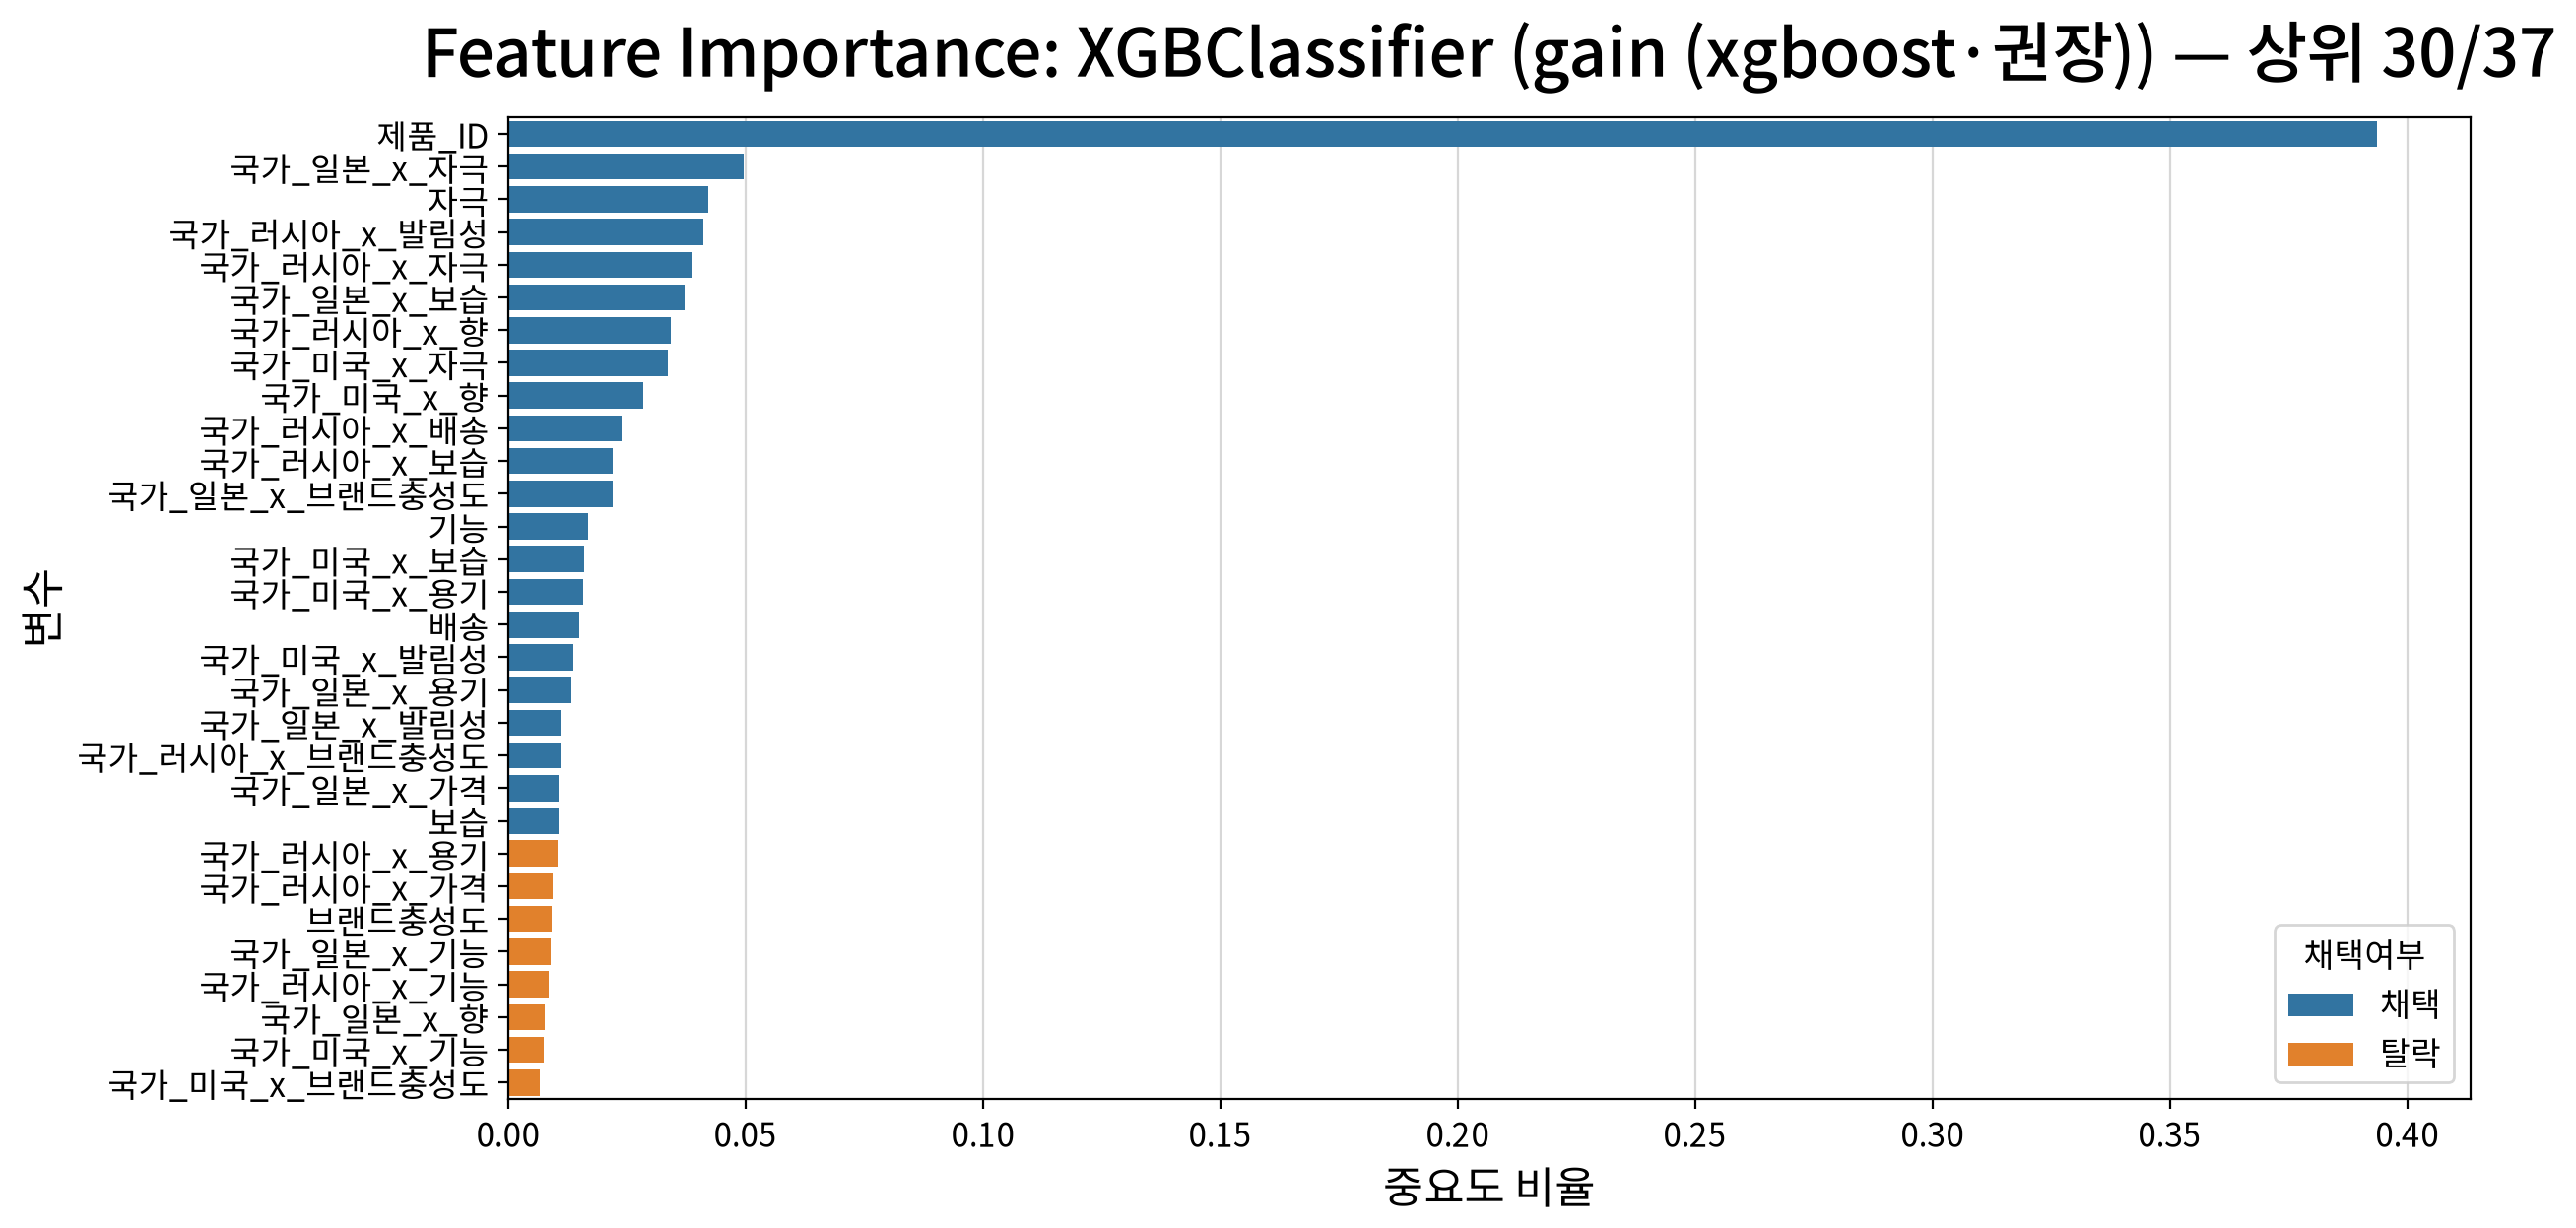


◆ Feature Importance: XGBClassifier  (중요도 기준=gain (xgboost·권장), 채택 기준=cum_ratio=90%)
   ▷ 탐색 객체의 best_params: {'model__learning_rate': 0.03, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 0.8}
   ▷ 원핫 더미 76개 → 원본 컬럼 37개로 중요도 합산
   전체 변수 37개 중 22개 채택 (누적 중요도 90.11% 설명)
   ▶ 채택된 변수: ['제품_ID', '국가_일본_x_자극', '자극', '국가_러시아_x_발림성', '국가_러시아_x_자극', '국가_일본_x_보습', '국가_러시아_x_향', '국가_미국_x_자극', '국가_미국_x_향', '국가_러시아_x_배송', '국가_러시아_x_보습', '국가_일본_x_브랜드충성도', '기능', '국가_미국_x_보습', '국가_미국_x_용기', '배송', '국가_미국_x_발림성', '국가_일본_x_용기', '국가_일본_x_발림성', '국가_러시아_x_브랜드충성도', '국가_일본_x_가격', '보습']



,Importance,Ratio,CumRatio,채택여부
Feature,,,,
제품_ID,153.597589,0.393693,0.393693,채택
국가_일본_x_자극,19.387066,0.049692,0.443385,채택
자극,16.463444,0.042198,0.485583,채택
국가_러시아_x_발림성,16.017637,0.041056,0.526639,채택
국가_러시아_x_자극,15.076725,0.038644,0.565282,채택
국가_일본_x_보습,14.510061,0.037191,0.602474,채택
국가_러시아_x_향,13.373327,0.034278,0.636752,채택
국가_미국_x_자극,13.110544,0.033604,0.670356,채택
국가_미국_x_향,11.136691,0.028545,0.698901,채택



누적 중요도 90%에 포함되는 변수(설명 참고용):
['제품_ID', '국가_일본_x_자극', '자극', '국가_러시아_x_발림성', '국가_러시아_x_자극', '국가_일본_x_보습', '국가_러시아_x_향', '국가_미국_x_자극', '국가_미국_x_향', '국가_러시아_x_배송', '국가_러시아_x_보습', '국가_일본_x_브랜드충성도', '기능', '국가_미국_x_보습', '국가_미국_x_용기', '배송', '국가_미국_x_발림성', '국가_일본_x_용기', '국가_일본_x_발림성', '국가_러시아_x_브랜드충성도', '국가_일본_x_가격', '보습']

※ 이 변수 목록으로 모델을 재선택/재튜닝하지 않습니다.


In [44]:
fi = my_ml.feature_importance(
    best_tuned,
    cum_ratio=0.90,
    aggregate_dummies=True,
    plot=True,
    verbose=True,
)

display(fi)

importance_90_features = fi.attrs.get(
    "selected_features",
    []
)

print("\n누적 중요도 90%에 포함되는 변수(설명 참고용):")
print(importance_90_features)

print("\n※ 이 변수 목록으로 모델을 재선택/재튜닝하지 않습니다.")


# 10. 🔒 최종 Test 평가 — 여기서 처음 사용

여기까지 다음이 모두 끝난 상태입니다.

1. 후보 모델 고정
2. Train 내부 CV 베이스라인 비교
3. Train 내부 CV 튜닝
4. 최종 모델 선택
5. Train/CV 과적합 진단
6. Feature Importance 해석

이제서야 **고정해 두었던 Test set을 최종 모델에 단 한 번 평가**합니다.

> 이 셀의 Test 성능을 보고 모델 종류, 하이퍼파라미터, 변수 구성을 다시 바꾸지 않습니다.


In [45]:
print("최종 모델:", FINAL_MODEL_KEY)
print("Best params:", best_tuned.best_params_)

# ---------------------------------------------------------
# ★ Test set 최초 모델 성능 평가
# ---------------------------------------------------------
final_test_score = my_ml.cls_score(
    best_tuned,
    x_test,
    y_test,
)

display(final_test_score)

# 최종 모델 저장
PROJECT_NAME = "skincare_product_control_clean"
final_dir = Path(PROJECT_NAME) / "final"
final_dir.mkdir(parents=True, exist_ok=True)

my_ml.save_model(
    best_tuned,
    final_dir / f"{FINAL_MODEL_KEY}.pkl",
)

print(
    "\n최종 모델 저장:",
    final_dir / f"{FINAL_MODEL_KEY}.pkl",
)


최종 모델: xgb
Best params: {'model__learning_rate': 0.03, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 0.8}


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
XGBClassifier,0.75333,0.788408,0.851433,0.818709,0.812588,0.893609,0.491263,0.43784



최종 모델 저장: skincare_product_control_clean\final\xgb.pkl


## 10-1. 최종 Test 결과 해석 원칙

최종 Test 결과는 **일반화 성능을 추정하기 위한 독립 평가값**으로 해석합니다.

- 모델 선정 기준: Train 내부 CV
- 최종 성능 보고: Test
- Test 결과를 보고 모델을 다시 선택하지 않음

따라서 기존 버전에서 발생했던 **Test → 모델 선택 → 다시 Test 평가**의 순환 구조를 제거했습니다.


In [46]:
# =========================================================
# 11. 🔍 신제품 일반화 강건성 검증
#    Repeated Product Group Holdout
# =========================================================

from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
)
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 11-1. Group 검증용 데이터 구성
# ---------------------------------------------------------

# 제품_ID는 예측변수가 아니라
# "어떤 제품에 속한 리뷰인가"를 구분하는 Group 기준으로만 사용
groups = X["제품_ID"].astype(str).copy()

# 신제품 검증에서는 제품_ID 자체를 예측변수에서 제외
X_group = X.drop(columns=["제품_ID"]).copy()

# 제품_ID prefix로 국가 주효과 복원
# 한국은 기준국가 → 세 더미가 모두 0
for col in ["국가_러시아", "국가_미국", "국가_일본"]:
    if col in X_group.columns:
        X_group = X_group.drop(columns=[col])

X_group.insert(
    0,
    "국가_러시아",
    groups.str.startswith("RU_").astype(int),
)

X_group.insert(
    1,
    "국가_미국",
    groups.str.startswith("US_").astype(int),
)

X_group.insert(
    2,
    "국가_일본",
    groups.str.startswith("JP_").astype(int),
)

print("Group 검증 X shape:", X_group.shape)
print("전체 제품 수:", groups.nunique())
print("메인 최종 모델:", FINAL_MODEL_KEY)
print("메인 최적 파라미터:", best_tuned.best_params_)


Group 검증 X shape: (6756, 39)
전체 제품 수: 40
메인 최종 모델: xgb
메인 최적 파라미터: {'model__learning_rate': 0.03, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 0.8}


In [47]:
# ---------------------------------------------------------
# 11-2. 검증 원칙
# ---------------------------------------------------------

# Group 검증에서 모델을 다시 경쟁시키지 않는다.
# 메인 Train-CV에서 이미 선택한 동일 알고리즘/하이퍼파라미터 사용

GROUP_MODEL_KEY = FINAL_MODEL_KEY
GROUP_BEST_PARAMS = best_tuned.best_params_.copy()

print("Group 검증 알고리즘:", GROUP_MODEL_KEY)
print("하이퍼파라미터 재탐색: 하지 않음")
print("제품_ID 입력 사용: 하지 않음")


Group 검증 알고리즘: xgb
하이퍼파라미터 재탐색: 하지 않음
제품_ID 입력 사용: 하지 않음


In [48]:
# ---------------------------------------------------------
# 11-3. 반복 Product Group Holdout
# ---------------------------------------------------------

N_GROUP_SPLITS = 20
GROUP_TEST_SIZE = 0.30

gss = GroupShuffleSplit(
    n_splits=N_GROUP_SPLITS,
    test_size=GROUP_TEST_SIZE,
    random_state=RANDOM_STATE,
)

group_rows = []
group_models = []

for split_no, (train_idx, test_idx) in enumerate(
    gss.split(X_group, y, groups=groups),
    start=1,
):
    xg_train = X_group.iloc[train_idx].copy()
    xg_test = X_group.iloc[test_idx].copy()

    yg_train = y.iloc[train_idx].copy()
    yg_test = y.iloc[test_idx].copy()

    gg_train = groups.iloc[train_idx].copy()
    gg_test = groups.iloc[test_idx].copy()

    # -----------------------------------------------------
    # 제품 중복 방지 확인
    # -----------------------------------------------------
    overlap = set(gg_train.unique()) & set(gg_test.unique())

    assert len(overlap) == 0, (
        f"Split {split_no}: "
        f"Train/Test 제품이 중복되었습니다: {overlap}"
    )

    # -----------------------------------------------------
    # 메인에서 선택된 동일 알고리즘으로 파이프라인 생성
    # -----------------------------------------------------
    group_pipe = build_pipeline(
        GROUP_MODEL_KEY,
        xg_train,
        yg_train,
    )

    # 메인 CV에서 확정된 하이퍼파라미터 그대로 재사용
    group_pipe.set_params(
        **GROUP_BEST_PARAMS
    )

    fit_kwargs = fit_kwargs_for(
        GROUP_MODEL_KEY,
        xg_train,
    )

    if fit_kwargs.get("model__cat_features") == []:
        fit_kwargs = {}

    # 각 split의 Train 제품으로 새로 fit
    group_pipe.fit(
        xg_train,
        yg_train,
        **fit_kwargs,
    )

    # -----------------------------------------------------
    # 처음 보는 제품으로 예측
    # -----------------------------------------------------
    pred = group_pipe.predict(xg_test)

    acc = accuracy_score(yg_test, pred)
    precision = precision_score(
        yg_test,
        pred,
        zero_division=0,
    )
    recall = recall_score(
        yg_test,
        pred,
        zero_division=0,
    )
    f1 = f1_score(
        yg_test,
        pred,
        zero_division=0,
    )
    mcc = matthews_corrcoef(
        yg_test,
        pred,
    )

    # ROC-AUC는 확률 또는 decision score가 있을 때만 계산
    roc_auc = np.nan

    try:
        if hasattr(group_pipe, "predict_proba"):
            score = group_pipe.predict_proba(xg_test)[:, 1]
            roc_auc = roc_auc_score(yg_test, score)

        elif hasattr(group_pipe, "decision_function"):
            score = group_pipe.decision_function(xg_test)
            roc_auc = roc_auc_score(yg_test, score)

    except Exception:
        roc_auc = np.nan

    group_rows.append({
        "Split": split_no,
        "Train_Reviews": len(xg_train),
        "Test_Reviews": len(xg_test),
        "Train_Products": gg_train.nunique(),
        "Test_Products": gg_test.nunique(),
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": mcc,
        "ROC_AUC": roc_auc,
    })

    group_models.append(group_pipe)

group_repeat_result = pd.DataFrame(group_rows)

display(group_repeat_result)


,Split,Train_Reviews,Test_Reviews,Train_Products,Test_Products,Accuracy,Precision,Recall,F1,MCC,ROC_AUC
0,1,4837,1919,28,12,0.775404,0.819347,0.895658,0.855805,0.359915,0.766874
1,2,4627,2129,28,12,0.697511,0.720996,0.800791,0.758801,0.359777,0.755564
2,3,4659,2097,28,12,0.721984,0.751507,0.841079,0.793774,0.376986,0.784161
3,4,4623,2133,28,12,0.721050,0.753024,0.851079,0.799054,0.355691,0.764495
4,5,4640,2116,28,12,0.726843,0.772487,0.786759,0.779558,0.420752,0.782851
5,6,4708,2048,28,12,0.706055,0.727774,0.836105,0.778187,0.356168,0.774369
6,7,4754,2002,28,12,0.776224,0.829814,0.876944,0.852728,0.391085,0.782621
7,8,4761,1995,28,12,0.775439,0.854004,0.832757,0.843247,0.448150,0.813311
8,9,4716,2040,28,12,0.675980,0.708614,0.776683,0.741089,0.312973,0.719344
9,10,4846,1910,28,12,0.728796,0.771817,0.844288,0.806428,0.360685,0.753388


In [49]:
# ---------------------------------------------------------
# 11-4. 반복 Group Holdout 결과 요약
# ---------------------------------------------------------

metric_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "MCC",
    "ROC_AUC",
]

group_summary = pd.DataFrame({
    "Mean": group_repeat_result[metric_cols].mean(),
    "STD": group_repeat_result[metric_cols].std(),
    "Min": group_repeat_result[metric_cols].min(),
    "Max": group_repeat_result[metric_cols].max(),
})

display(group_summary)

print("=" * 70)
print("신제품 일반화 반복 검증")
print("=" * 70)

print(
    f"F1  : "
    f"{group_summary.loc['F1', 'Mean']:.3f} "
    f"± {group_summary.loc['F1', 'STD']:.3f}"
)

print(
    f"MCC : "
    f"{group_summary.loc['MCC', 'Mean']:.3f} "
    f"± {group_summary.loc['MCC', 'STD']:.3f}"
)

print(
    f"Precision : "
    f"{group_summary.loc['Precision', 'Mean']:.3f} "
    f"± {group_summary.loc['Precision', 'STD']:.3f}"
)

print(
    f"Recall    : "
    f"{group_summary.loc['Recall', 'Mean']:.3f} "
    f"± {group_summary.loc['Recall', 'STD']:.3f}"
)


,Mean,STD,Min,Max
Accuracy,0.723824,0.032087,0.674727,0.783351
Precision,0.762691,0.041764,0.708604,0.854004
Recall,0.828363,0.033985,0.775930,0.895658
F1,0.793859,0.034880,0.740741,0.856458
MCC,0.369876,0.039502,0.302112,0.448150
ROC_AUC,0.767417,0.024719,0.719344,0.813311


신제품 일반화 반복 검증
F1  : 0.794 ± 0.035
MCC : 0.370 ± 0.040
Precision : 0.763 ± 0.042
Recall    : 0.828 ± 0.034


In [50]:
# ---------------------------------------------------------
# 11-5. 메인 Test와 Group 검증의 해석 구분
# ---------------------------------------------------------

print("=" * 80)
print("메인 Test")
print("=" * 80)
print(
    "분석 대상 40개 제품군 내에서 "
    "새로운 리뷰를 분류하는 성능"
)
print(
    "- 제품_ID 포함"
)
print(
    "- 리뷰 단위 Random Split"
)
display(final_test_score)

print("\n" + "=" * 80)
print("추가 Group 검증")
print("=" * 80)
print(
    "학습에서 한 번도 보지 못한 제품에 대한 "
    "일반화 가능성"
)
print(
    "- 제품_ID를 예측변수에서 제외"
)
print(
    f"- 제품 단위 Group Holdout {N_GROUP_SPLITS}회 반복"
)
print(
    "- 메인과 동일 알고리즘 및 동일 하이퍼파라미터 사용"
)

display(group_summary)


메인 Test
분석 대상 40개 제품군 내에서 새로운 리뷰를 분류하는 성능
- 제품_ID 포함
- 리뷰 단위 Random Split


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
XGBClassifier,0.75333,0.788408,0.851433,0.818709,0.812588,0.893609,0.491263,0.43784



추가 Group 검증
학습에서 한 번도 보지 못한 제품에 대한 일반화 가능성
- 제품_ID를 예측변수에서 제외
- 제품 단위 Group Holdout 20회 반복
- 메인과 동일 알고리즘 및 동일 하이퍼파라미터 사용


,Mean,STD,Min,Max
Accuracy,0.723824,0.032087,0.674727,0.783351
Precision,0.762691,0.041764,0.708604,0.854004
Recall,0.828363,0.033985,0.775930,0.895658
F1,0.793859,0.034880,0.740741,0.856458
MCC,0.369876,0.039502,0.302112,0.448150
ROC_AUC,0.767417,0.024719,0.719344,0.813311


## 11-6. Group Holdout 결과 해석 원칙

메인 Test와 Group Holdout은 서로 다른 일반화 범위를 평가한다.

- **메인 Test**: 분석 대상 40개 제품군 내에서 새로운 리뷰가 입력되었을 때의 성능
- **Group Holdout**: 학습에서 한 번도 보지 못한 새로운 제품의 리뷰에 대한 일반화 가능성

Group Holdout에서는 제품 고유 정보에 직접 의존하지 않도록 `제품_ID`를 예측변수에서 제외하였으며,
메인 분석에서 선정된 동일 알고리즘과 동일 하이퍼파라미터를 유지하였다.

또한 특정 Test 제품 조합에 따라 성능이 달라질 가능성을 고려하여
단일 분할 결과가 아닌 **20회 반복 Product Group Holdout의 평균과 표준편차**를 확인하였다.

신제품 일반화 성능은 F1 하나만으로 판단하지 않고
**Precision, Recall, MCC를 함께 확인**하였다.

특히 F1이 높더라도 Recall 증가에 의해 성능이 높아질 수 있으므로,
혼동행렬 전체 정보를 반영하는 MCC가 낮게 나타날 경우
"신제품에서 성능이 더 우수하다"고 해석하지 않는다.

따라서 본 검증은 메인 모델의 Test 성능을 대체하기 위한 것이 아니라,
**제품 고유 특성에 의존하지 않았을 때도 만족·불만족 분류 구조가 어느 정도 유지되는지를 확인하기 위한 추가 강건성 검증**으로 해석한다.


# 11. SHAP 분석 — `제품_ID` 원본 변수 단위로 통합

최종 모델이 확정되고 Test 평가까지 끝난 뒤 SHAP을 사용해 **예측 결과를 설명**합니다.

## 기존 그래프에서 제품 ID가 여러 개로 나뉜 이유

`제품_ID`는 명목형 변수이므로 XGBoost·LightGBM 등에서는 학습 전에 One-Hot Encoding됩니다.

```text
제품_ID
↓
제품_ID_JP_P01
제품_ID_JP_P02
제품_ID_RU_P01
...
```

SHAP은 모델이 실제 학습한 **변환 후 피처공간**에서 계산되므로 기존 Bar에서는
`제품_ID_JP_P07`, `제품_ID_RU_P09`처럼 개별 제품 더미가 각각 표시되었습니다.

하지만 본 프로젝트에서 `제품_ID`는 **제품 자체 차이를 통제하기 위한 하나의 원본 변수**입니다.
따라서 보고용 Global SHAP에서는 모든 `제품_ID_*` 더미를 **`제품_ID` 하나로 통합**하여 해석합니다.

### 통합 원칙

각 관측치에서 제품 더미들의 SHAP 값을 먼저 합산한 뒤, 그 합산값의 `mean(|SHAP|)`을 계산합니다.

> 즉, 더미별 `mean(|SHAP|)`을 단순 더하는 것이 아니라  
> **행별 기여도를 먼저 합친 뒤 절댓값 평균을 계산**합니다.

`제품_ID`는 여러 제품 범주가 합쳐진 명목형 통제변수이므로 **전체 방향(+/-)은 해석하지 않고 중요도만 해석**합니다.


In [53]:
# =========================================================
# 11-1. XGBoost Native TreeSHAP 계산
# shap 패키지를 사용하지 않고 XGBoost 자체 SHAP 계산 사용
# =========================================================

import numpy as np
import pandas as pd
import xgboost as xgb

# ---------------------------------------------------------
# 최종 모델 불러오기
# ---------------------------------------------------------

final_model = my_ml.load_model(
    final_dir / f"{FINAL_MODEL_KEY}.pkl"
)

# GridSearchCV로 저장된 경우 최적 파이프라인 꺼내기
base_pipe = getattr(
    final_model,
    "best_estimator_",
    final_model
)

# ---------------------------------------------------------
# 파이프라인 내부 전처리기 / XGBoost 모델 분리
# ---------------------------------------------------------

preprocessor = base_pipe.named_steps["preprocessor"]
xgb_model = base_pipe.named_steps["model"]

print("최종 모델 클래스:", xgb_model.__class__.__name__)

# ---------------------------------------------------------
# SHAP 계산 표본
# 기존 코드와 동일하게 최대 200건 사용
# ---------------------------------------------------------

X_shap_source = x_test.sample(
    n=min(200, len(x_test)),
    random_state=RANDOM_STATE
)

# 모델이 실제 학습한 형태로 변환
X_shap_model = preprocessor.transform(
    X_shap_source
)

# 혹시 ndarray로 반환되면 DataFrame으로 복원
if not isinstance(X_shap_model, pd.DataFrame):

    feature_names = list(
        preprocessor.get_feature_names_out()
    )

    X_shap_model = pd.DataFrame(
        X_shap_model,
        index=X_shap_source.index,
        columns=feature_names
    )

else:
    X_shap_model = X_shap_model.copy()

X_shap_model.columns = (
    X_shap_model.columns.astype(str)
)

# ---------------------------------------------------------
# XGBoost Native TreeSHAP
# ---------------------------------------------------------

booster = xgb_model.get_booster()

# 학습 당시 feature 순서가 있으면 동일하게 맞춤
booster_features = booster.feature_names

if booster_features is not None:
    if set(booster_features) == set(X_shap_model.columns):
        X_shap_model = X_shap_model[
            booster_features
        ]

dmat = xgb.DMatrix(
    X_shap_model
)

# 마지막 열은 bias(expected value)
contrib = booster.predict(
    dmat,
    pred_contribs=True
)

shap_values = contrib[:, :-1]
bias_values = contrib[:, -1]

feature_names = list(
    X_shap_model.columns
)

expected_value = float(
    np.mean(bias_values)
)

# ---------------------------------------------------------
# SHAP 계산 검증
# SHAP 합계 = XGBoost output margin(log-odds)
# ---------------------------------------------------------

native_margin = booster.predict(
    dmat,
    output_margin=True
)

shap_margin = contrib.sum(axis=1)

max_gap = np.max(
    np.abs(native_margin - shap_margin)
)

print(
    "SHAP 합계 검증 최대 오차:",
    max_gap
)

# ---------------------------------------------------------
# 기존 이후 코드와 호환되는 shap_result 생성
# ---------------------------------------------------------

shap_result = pd.DataFrame({
    "mean_abs_shap": np.abs(
        shap_values
    ).mean(axis=0),

    "mean_shap": shap_values.mean(
        axis=0
    ),

    "std_shap": shap_values.std(
        axis=0
    ),
}, index=feature_names)

shap_result = shap_result.sort_values(
    "mean_abs_shap",
    ascending=False
)

total = shap_result[
    "mean_abs_shap"
].sum()

shap_result["ratio"] = (
    shap_result["mean_abs_shap"]
    / total
)

shap_result["cum_ratio"] = (
    shap_result["ratio"].cumsum()
)

# 이후 셀과 호환되도록 attrs 저장
shap_result.attrs[
    "shap_values"
] = shap_values

shap_result.attrs[
    "data"
] = X_shap_model

shap_result.attrs[
    "feature_names"
] = feature_names

shap_result.attrs[
    "expected_value"
] = expected_value

print(
    "\nRaw SHAP 결과:"
    " XGBoost Native TreeSHAP"
)

display(
    shap_result.head(20)
)

최종 모델 클래스: XGBClassifier
SHAP 합계 검증 최대 오차: 2.6226044e-06

Raw SHAP 결과: XGBoost Native TreeSHAP


,mean_abs_shap,mean_shap,std_shap,ratio,cum_ratio
자극,0.511115,0.002987,0.536672,0.188828,0.188828
기능,0.283926,0.042161,0.322818,0.104895,0.293723
보습,0.186186,-0.012100,0.207562,0.068785,0.362508
배송,0.112272,0.022315,0.210790,0.041478,0.403986
국가_일본_x_보습,0.107021,0.004938,0.209587,0.039538,0.443524
국가_러시아_x_향,0.106918,0.001825,0.218163,0.039500,0.483025
국가_미국_x_보습,0.088431,-0.010974,0.126012,0.032670,0.515695
국가_러시아_x_발림성,0.077352,0.011294,0.138436,0.028577,0.544272
발림성,0.076098,0.006589,0.087015,0.028114,0.572386
국가_미국_x_자극,0.074054,0.020954,0.103896,0.027359,0.599745


## 11-2. `제품_ID_*` → `제품_ID` 통합

아래 셀에서는 One-Hot으로 분리된 제품 더미들의 SHAP 값을 **관측치별로 합산**합니다.

나머지 9개 속성과 국가×속성 변수는 원래 이름을 그대로 유지합니다.


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def aggregate_product_id_shap(result, product_col="제품_ID"):
    """
    제품_ID One-Hot 더미들을 원본 제품_ID 하나의 SHAP 기여도로 통합한다.

    계산 순서:
    1) 각 행에서 제품_ID_* SHAP 값을 합산
    2) 합산된 행별 기여도의 mean(abs()) 계산
    """
    shap_values = np.asarray(result.attrs["shap_values"])
    model_data = result.attrs["data"]
    feature_names = list(result.attrs["feature_names"])

    if shap_values.ndim != 2:
        raise ValueError(f"SHAP shape 오류: {shap_values.shape}")

    groups = []
    group_to_indices = {}

    for j, feature in enumerate(feature_names):
        if feature == product_col or feature.startswith(product_col + "_"):
            group = product_col
        else:
            group = feature

        if group not in group_to_indices:
            groups.append(group)
            group_to_indices[group] = []

        group_to_indices[group].append(j)

    grouped_values = np.column_stack([
        shap_values[:, group_to_indices[g]].sum(axis=1)
        for g in groups
    ])

    grouped_shap_df = pd.DataFrame(
        grouped_values,
        index=model_data.index,
        columns=groups,
    )

    grouped_summary = pd.DataFrame({
        "mean_abs_shap": grouped_shap_df.abs().mean(),
        "mean_shap": grouped_shap_df.mean(),
        "std_shap": grouped_shap_df.std(),
    }).sort_values("mean_abs_shap", ascending=False)

    total = grouped_summary["mean_abs_shap"].sum()

    if total > 0:
        grouped_summary["ratio"] = grouped_summary["mean_abs_shap"] / total
    else:
        grouped_summary["ratio"] = 0.0

    grouped_summary["cum_ratio"] = grouped_summary["ratio"].cumsum()

    grouped_summary["direction"] = np.where(
        grouped_summary["mean_shap"] > 0,
        "증가",
        np.where(grouped_summary["mean_shap"] < 0, "감소", "중립"),
    )

    if product_col in grouped_summary.index:
        grouped_summary.loc[product_col, "direction"] = "방향 해석 안 함"

    grouped_summary.attrs["grouped_shap_values"] = grouped_values
    grouped_summary.attrs["grouped_shap_df"] = grouped_shap_df
    grouped_summary.attrs["expected_value"] = result.attrs["expected_value"]

    return grouped_summary


shap_grouped = aggregate_product_id_shap(
    shap_result,
    product_col="제품_ID",
)

print("원본 변수 단위 SHAP 중요도")
display(shap_grouped.head(25))


원본 변수 단위 SHAP 중요도


,mean_abs_shap,mean_shap,std_shap,ratio,cum_ratio,direction
자극,0.511115,0.002987,0.538019,0.208005,0.208005,증가
제품_ID,0.395055,0.094869,0.635954,0.160773,0.368778,방향 해석 안 함
기능,0.283926,0.042161,0.323628,0.115548,0.484326,증가
보습,0.186186,-0.012100,0.208083,0.075771,0.560097,감소
배송,0.112272,0.022315,0.211319,0.045690,0.605788,증가
국가_일본_x_보습,0.107021,0.004938,0.210113,0.043554,0.649341,증가
국가_러시아_x_향,0.106918,0.001825,0.218711,0.043512,0.692853,증가
국가_미국_x_보습,0.088431,-0.010974,0.126328,0.035988,0.728841,감소
국가_러시아_x_발림성,0.077352,0.011294,0.138784,0.031480,0.760321,증가
발림성,0.076098,0.006589,0.087234,0.030969,0.791290,증가


## 11-3. Global SHAP Bar — `제품_ID` 한 줄로 표시

이 그래프를 **보고서용 전역 SHAP 중요도**로 사용합니다.

- 개별 `제품_ID_JP_P07`, `제품_ID_RU_P09` 등은 표시하지 않음
- 모든 제품 더미의 기여도는 `제품_ID` 하나로 통합
- 9개 속성과 국가×속성은 그대로 유지


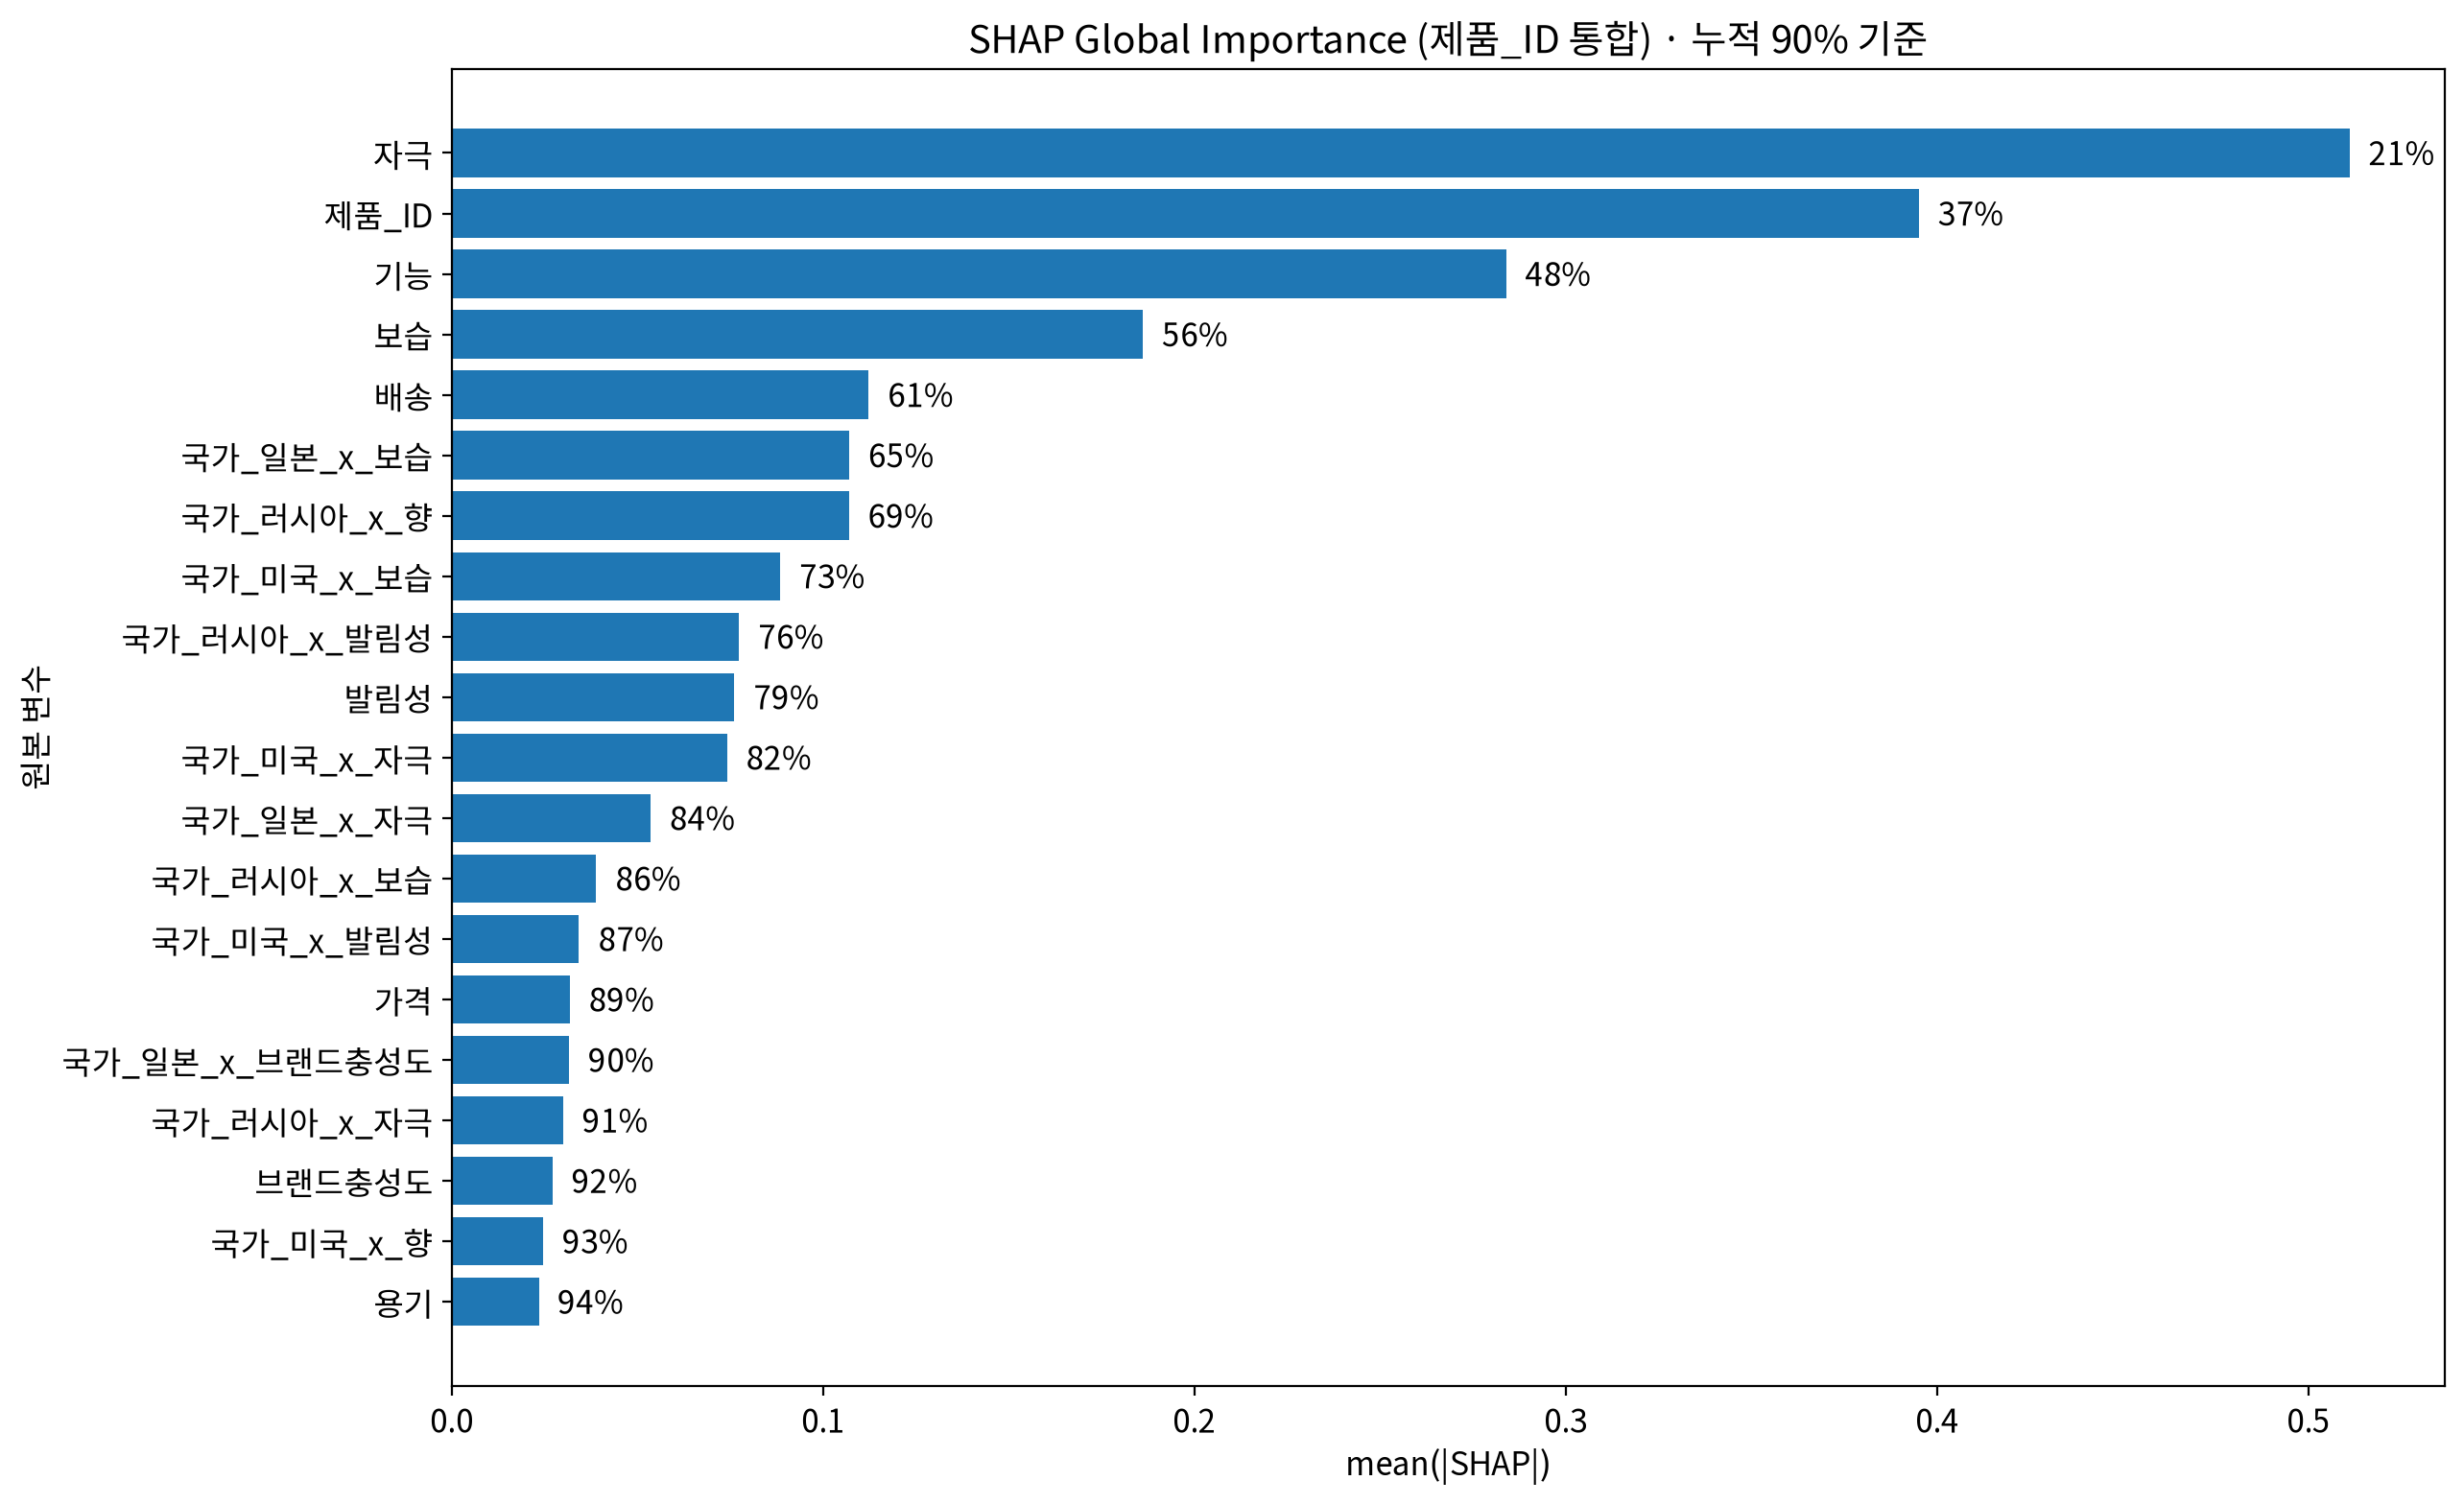

누적 90% 도달 변수 수: 17


,mean_abs_shap,mean_shap,std_shap,ratio,cum_ratio,direction
자극,0.511115,0.002987,0.538019,0.208005,0.208005,증가
제품_ID,0.395055,0.094869,0.635954,0.160773,0.368778,방향 해석 안 함
기능,0.283926,0.042161,0.323628,0.115548,0.484326,증가
보습,0.186186,-0.012100,0.208083,0.075771,0.560097,감소
배송,0.112272,0.022315,0.211319,0.045690,0.605788,증가
국가_일본_x_보습,0.107021,0.004938,0.210113,0.043554,0.649341,증가
국가_러시아_x_향,0.106918,0.001825,0.218711,0.043512,0.692853,증가
국가_미국_x_보습,0.088431,-0.010974,0.126328,0.035988,0.728841,감소
국가_러시아_x_발림성,0.077352,0.011294,0.138784,0.031480,0.760321,증가
발림성,0.076098,0.006589,0.087234,0.030969,0.791290,증가


In [55]:
CUM_RATIO = 0.90
MAX_DISPLAY = 20

plot_df = shap_grouped.head(MAX_DISPLAY).copy()

k = int(np.searchsorted(
    shap_grouped["cum_ratio"].values,
    CUM_RATIO,
)) + 1
k = max(1, min(k, len(shap_grouped)))

fig, ax = plt.subplots(figsize=(13, 8))

y = np.arange(len(plot_df))
ax.barh(y, plot_df["mean_abs_shap"].values)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.invert_yaxis()
ax.set_xlabel("mean(|SHAP|)")
ax.set_ylabel("원본 변수")
ax.set_title(
    f"SHAP Global Importance (제품_ID 통합) · 누적 {CUM_RATIO:.0%} 기준"
)

vmax = float(plot_df["mean_abs_shap"].max())

for i, (_, row) in enumerate(plot_df.iterrows()):
    ax.text(
        row["mean_abs_shap"] + vmax * 0.01,
        i,
        f'{row["cum_ratio"]:.0%}',
        va="center",
    )

plt.tight_layout()
plt.show()

selected_grouped = shap_grouped.iloc[:k].copy()
print(f"누적 {CUM_RATIO:.0%} 도달 변수 수: {k}")
display(selected_grouped)


## 11-4. 방향 해석용 Beeswarm — 제품 ID 제외

`제품_ID`는 제품별 차이를 통제하는 명목형 변수라 하나의 “높음/낮음” 방향으로 해석하기 어렵습니다.

따라서 방향을 확인하는 Beeswarm에서는 제품 더미를 제외하고
**9개 속성과 국가×속성**을 중심으로 확인합니다.


Beeswarm 표시 변수:
['자극', '기능', '보습', '배송', '국가_일본_x_보습', '국가_러시아_x_향', '국가_미국_x_보습', '국가_러시아_x_발림성', '발림성', '국가_미국_x_자극', '국가_일본_x_자극', '국가_러시아_x_보습', '국가_미국_x_발림성', '가격', '국가_일본_x_브랜드충성도', '국가_러시아_x_자극', '브랜드충성도', '국가_미국_x_향', '용기', '국가_러시아_x_용기']


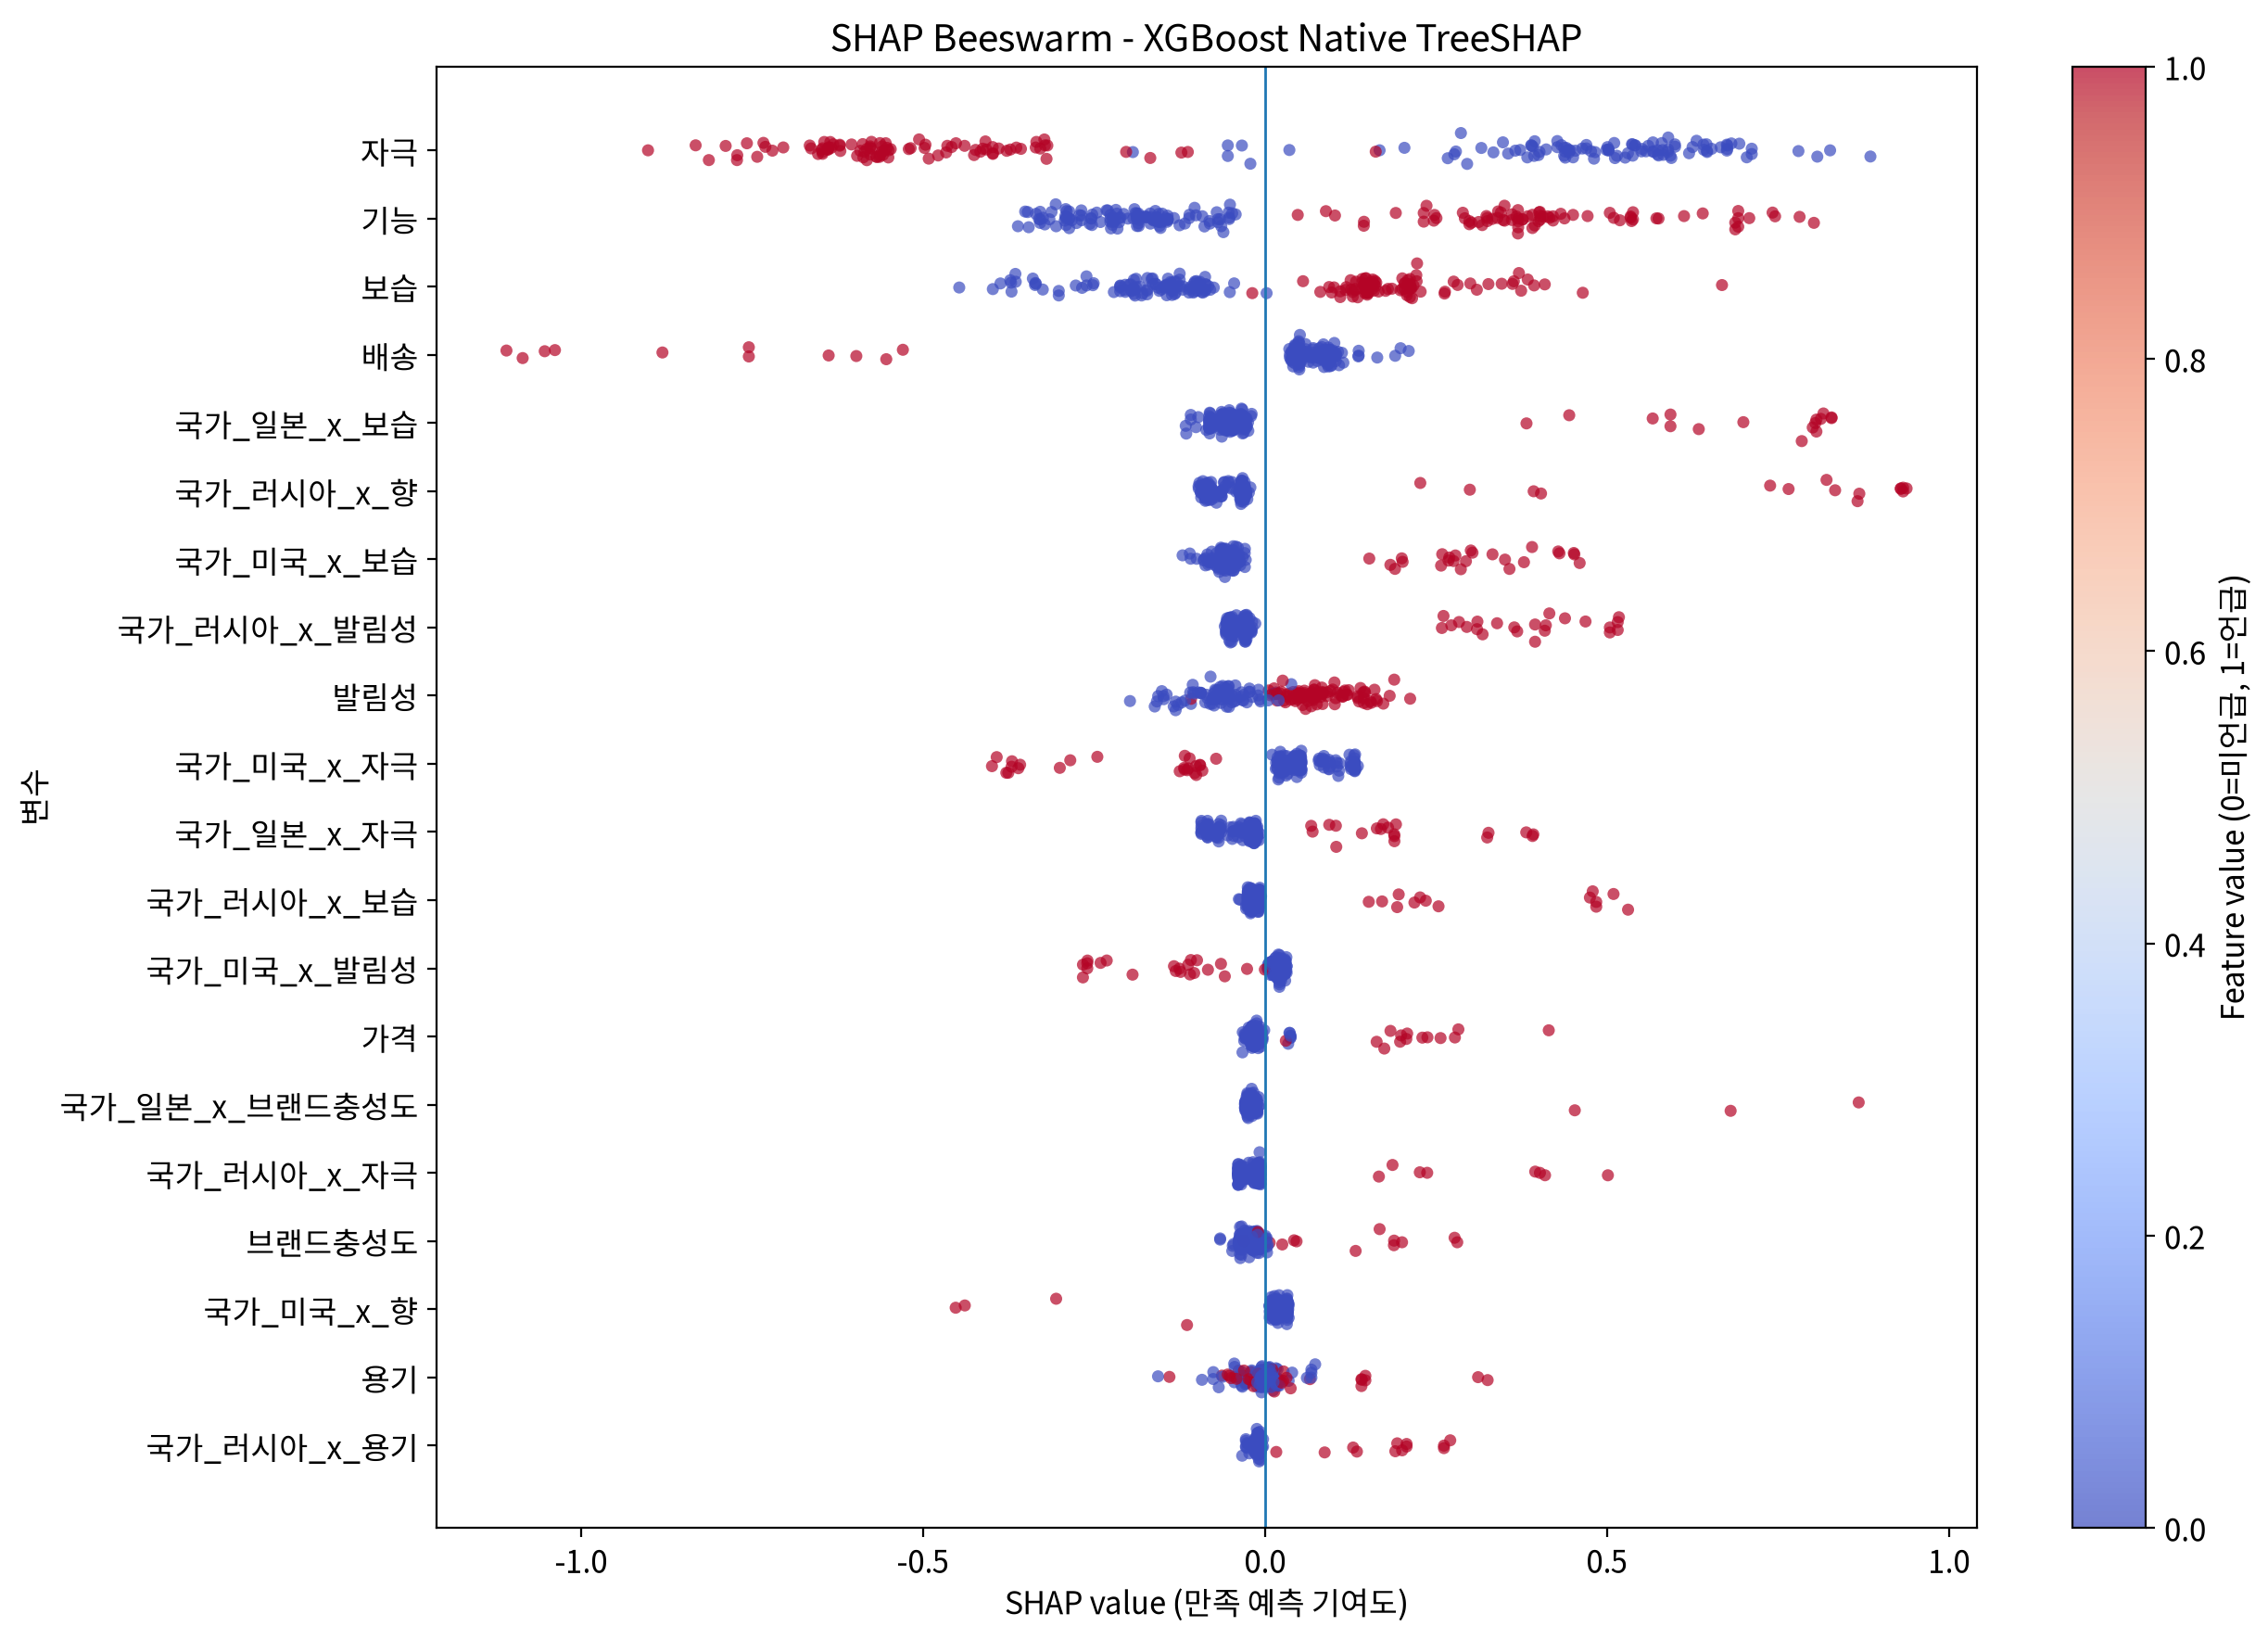

In [57]:
# =========================================================
# 11-4. 방향 해석용 SHAP Beeswarm
# XGBoost Native TreeSHAP 값 사용
# shap 패키지 사용 안 함
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

raw_values = np.asarray(
    shap_result.attrs["shap_values"]
)

raw_data = shap_result.attrs["data"]

raw_features = list(
    shap_result.attrs["feature_names"]
)

# 제품_ID 관련 더미 제외
non_product_features = [
    f
    for f in raw_features
    if not (
        f == "제품_ID"
        or f.startswith("제품_ID_")
    )
]

# SHAP 중요도 순서 유지
non_product_rank = [
    f
    for f in shap_result.index
    if f in non_product_features
]

TOP_K = min(
    20,
    len(non_product_rank)
)

beeswarm_features = (
    non_product_rank[:TOP_K]
)

print("Beeswarm 표시 변수:")
print(beeswarm_features)

rng = np.random.default_rng(
    RANDOM_STATE
)

fig, ax = plt.subplots(
    figsize=(13, 9)
)

last_scatter = None

for y_pos, feature in enumerate(
    beeswarm_features
):

    j = raw_features.index(feature)

    shap_v = raw_values[:, j]

    feature_v = (
        raw_data.iloc[:, j]
        .astype(float)
        .to_numpy()
    )

    # 점이 겹치지 않도록 세로 방향으로 약간 분산
    jitter = rng.normal(
        0,
        0.08,
        size=len(shap_v)
    )

    y = (
        np.full(
            len(shap_v),
            y_pos
        )
        + jitter
    )

    last_scatter = ax.scatter(
        shap_v,
        y,
        c=feature_v,
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        s=22,
        alpha=0.70,
        edgecolors="none",
    )

ax.axvline(
    0,
    linewidth=1
)

ax.set_yticks(
    np.arange(
        len(beeswarm_features)
    )
)

ax.set_yticklabels(
    beeswarm_features
)

ax.invert_yaxis()

ax.set_xlabel(
    "SHAP value (만족 예측 기여도)"
)

ax.set_ylabel(
    "변수"
)

ax.set_title(
    "SHAP Beeswarm - XGBoost Native TreeSHAP"
)

if last_scatter is not None:
    cbar = plt.colorbar(
        last_scatter,
        ax=ax
    )

    cbar.set_label(
        "Feature value (0=미언급, 1=언급)"
    )

plt.tight_layout()
plt.show()

## 11-5. Dependence Plot — 제품 더미 제외

Dependence Plot 역시 개별 제품 더미보다 **실제 해석 대상인 속성·국가×속성**을 중심으로 확인합니다.


SHAP interaction shape: (200, 76, 76)


,feature,interaction_feature,mean_abs_interaction
0,자극,기능,0.078991
1,기능,자극,0.078991
2,보습,자극,0.033034
3,배송,자극,0.029119
4,국가_일본_x_보습,자극,0.019537
5,국가_러시아_x_향,자극,0.037791
6,국가_미국_x_보습,자극,0.009304
7,국가_러시아_x_발림성,자극,0.015094
8,발림성,기능,0.019579
9,국가_미국_x_자극,보습,0.027581


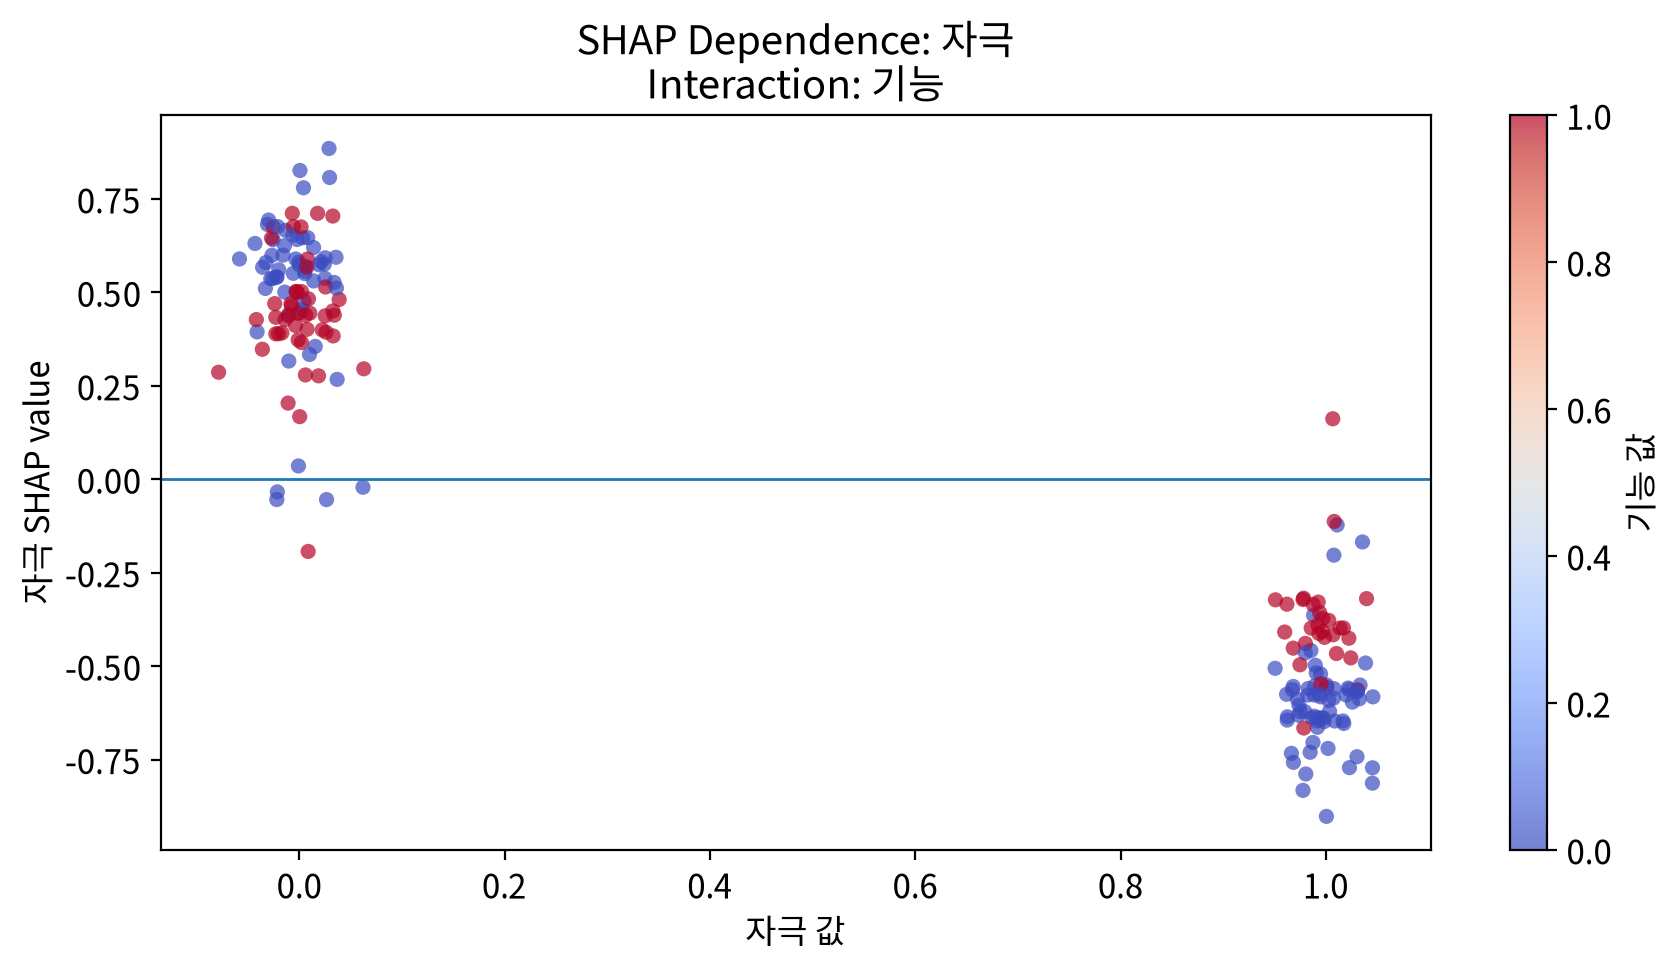

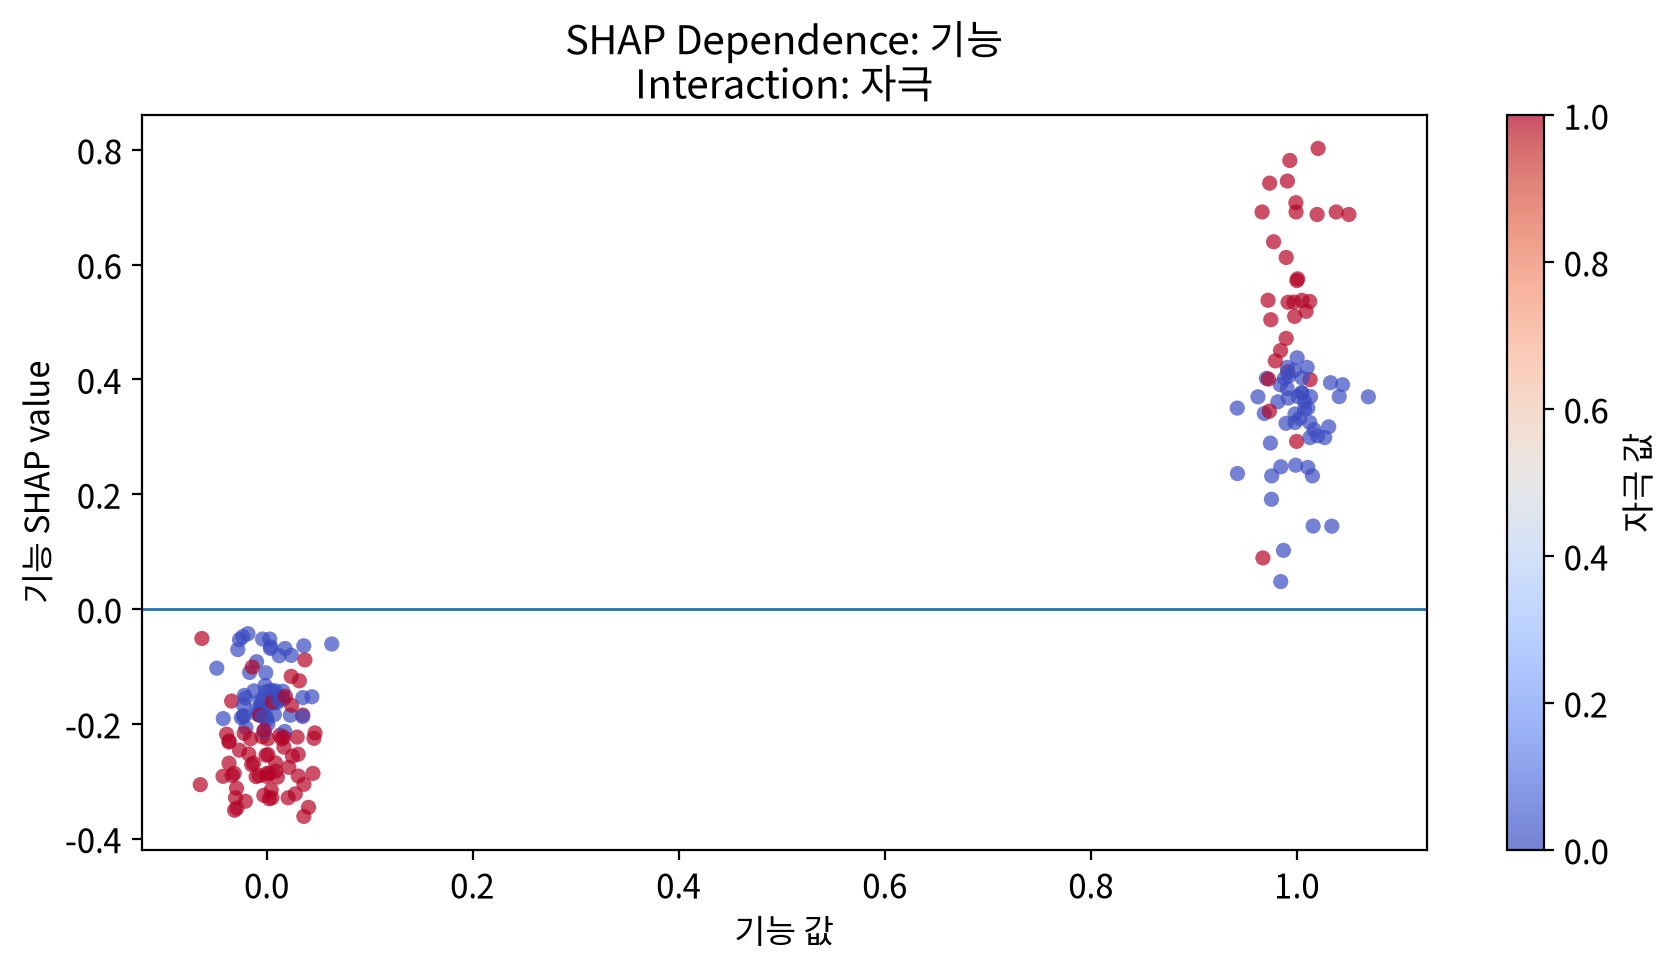

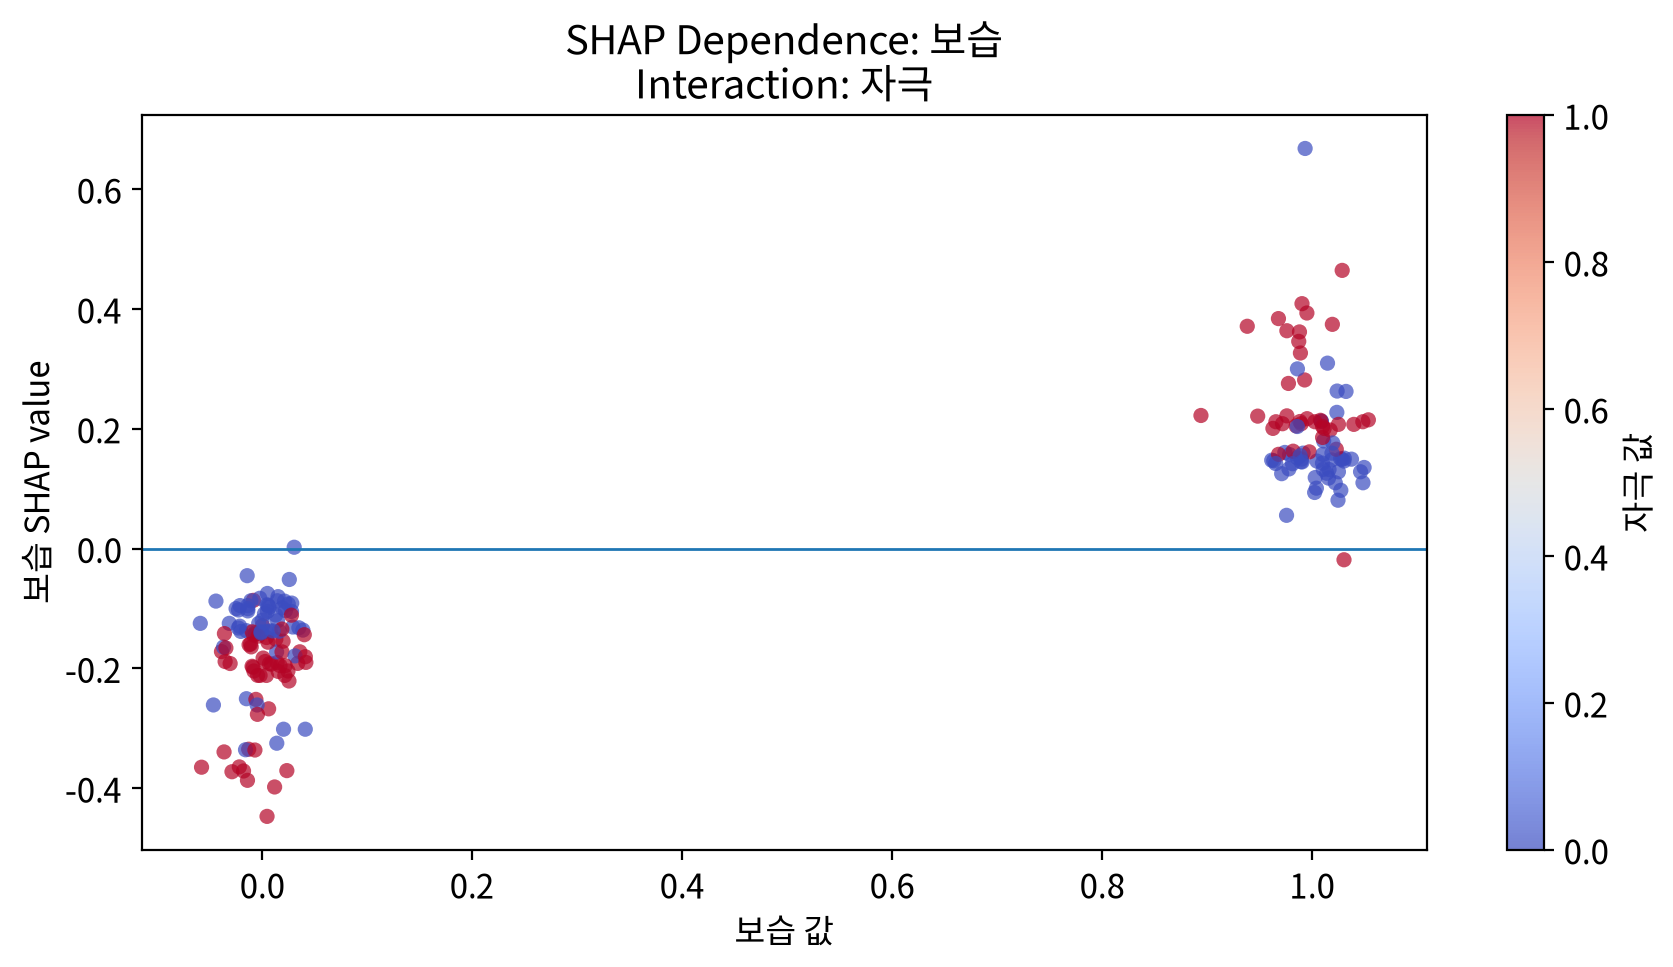

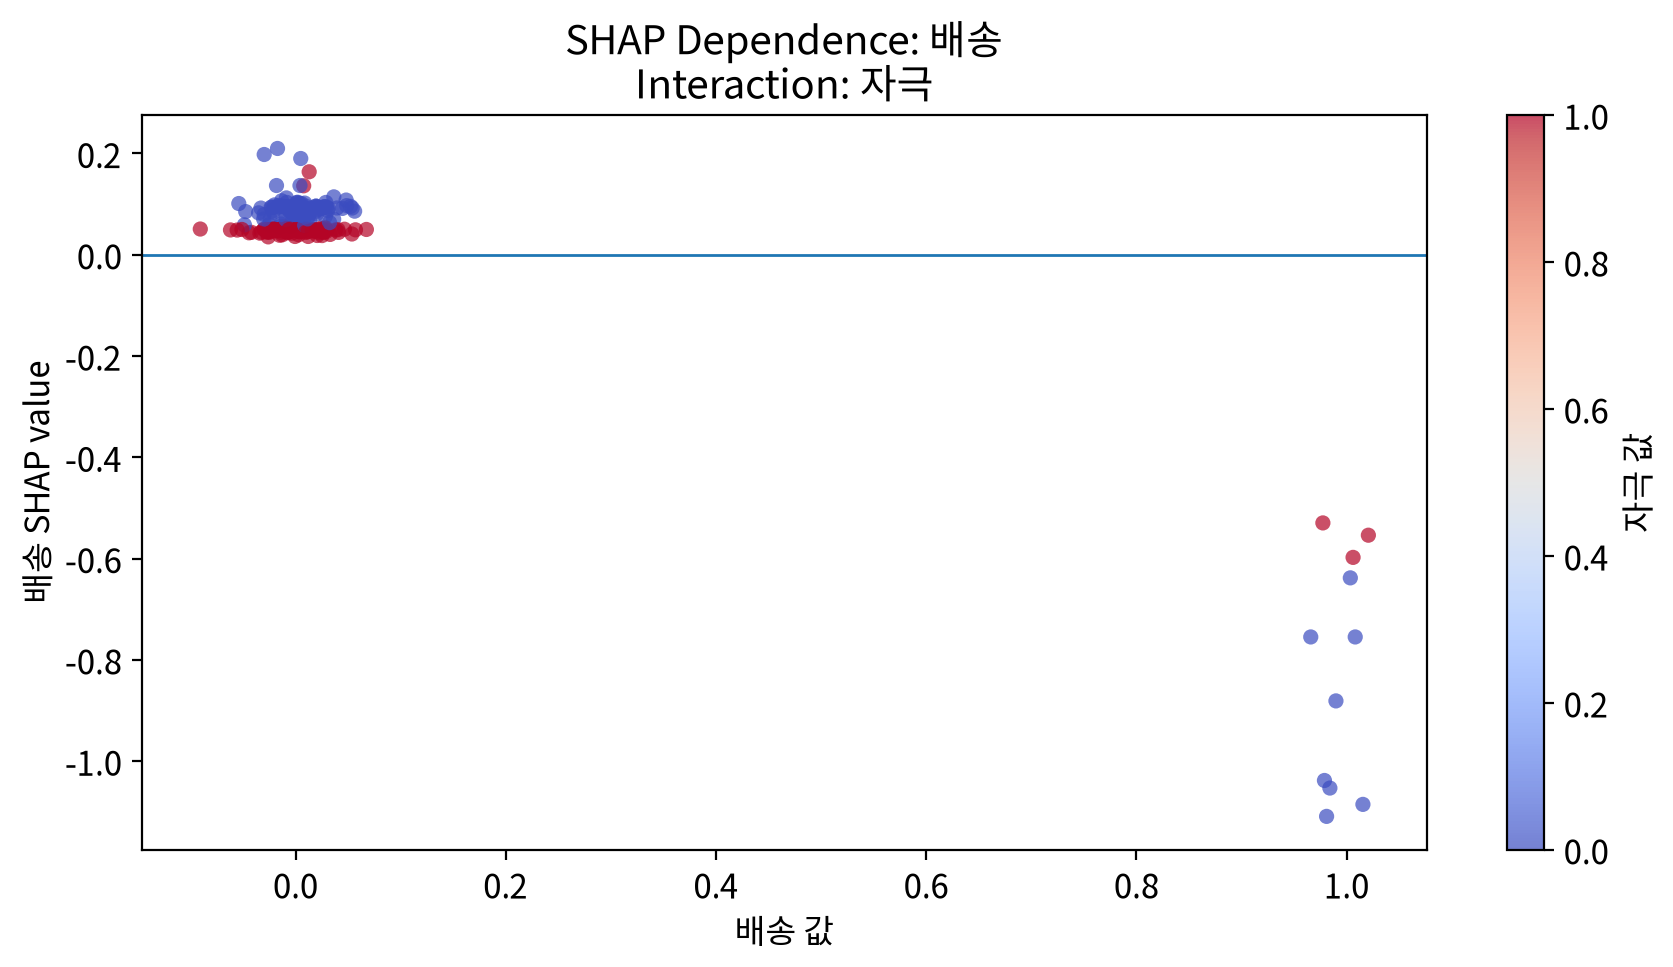

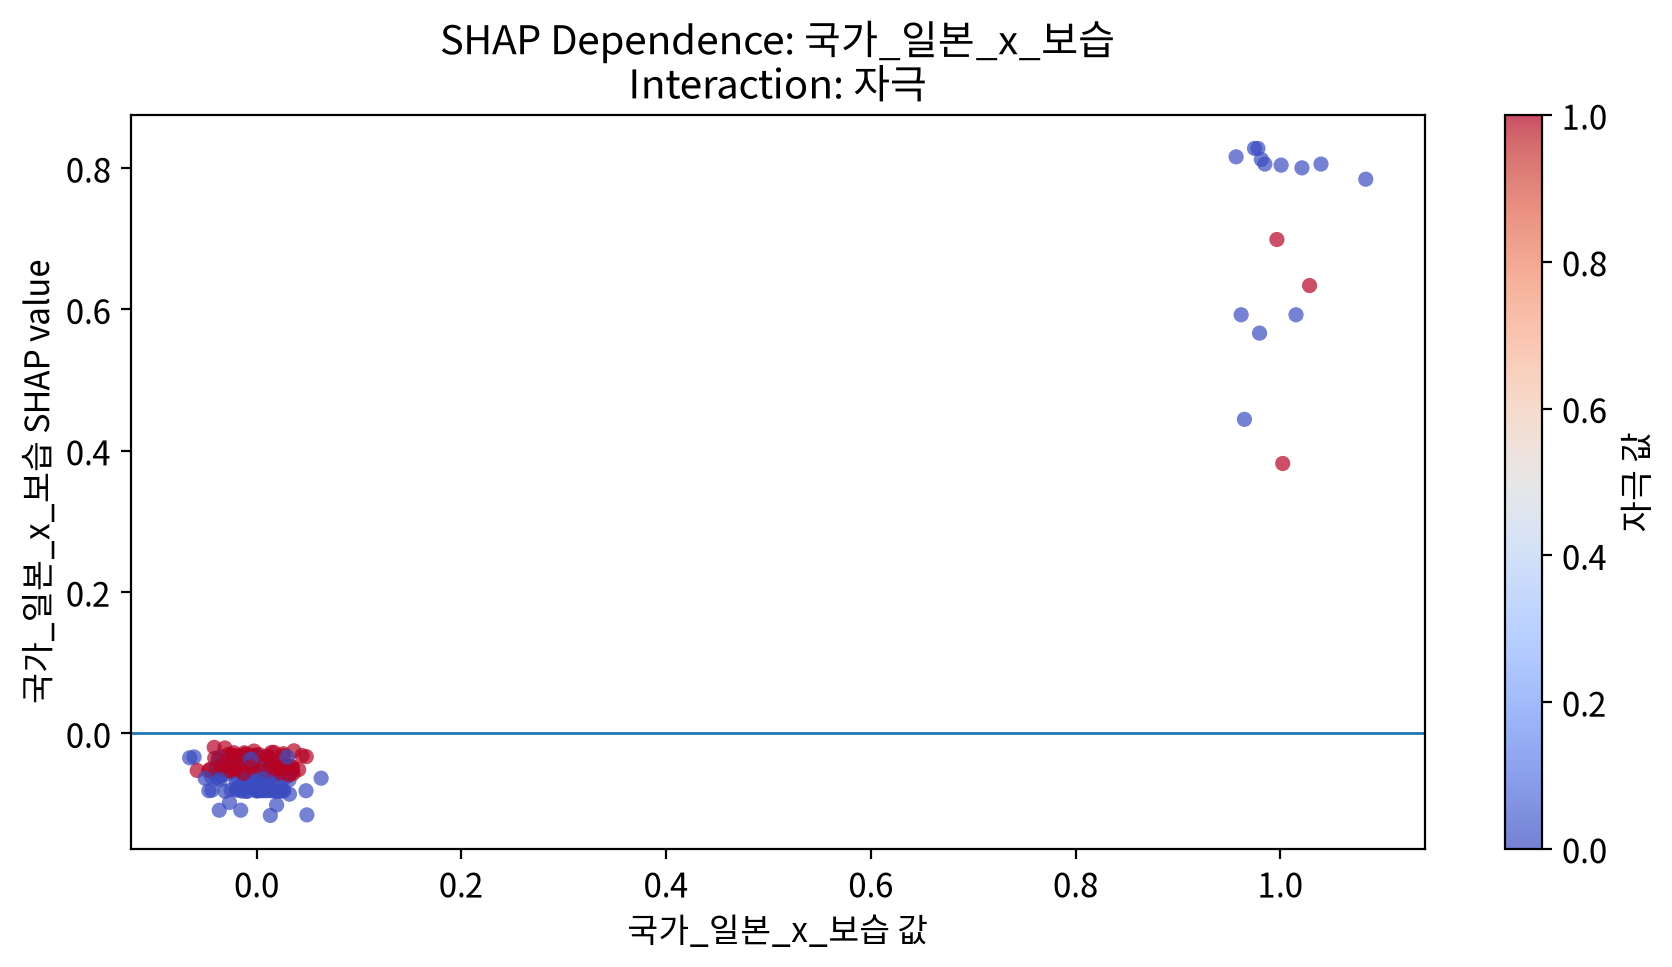

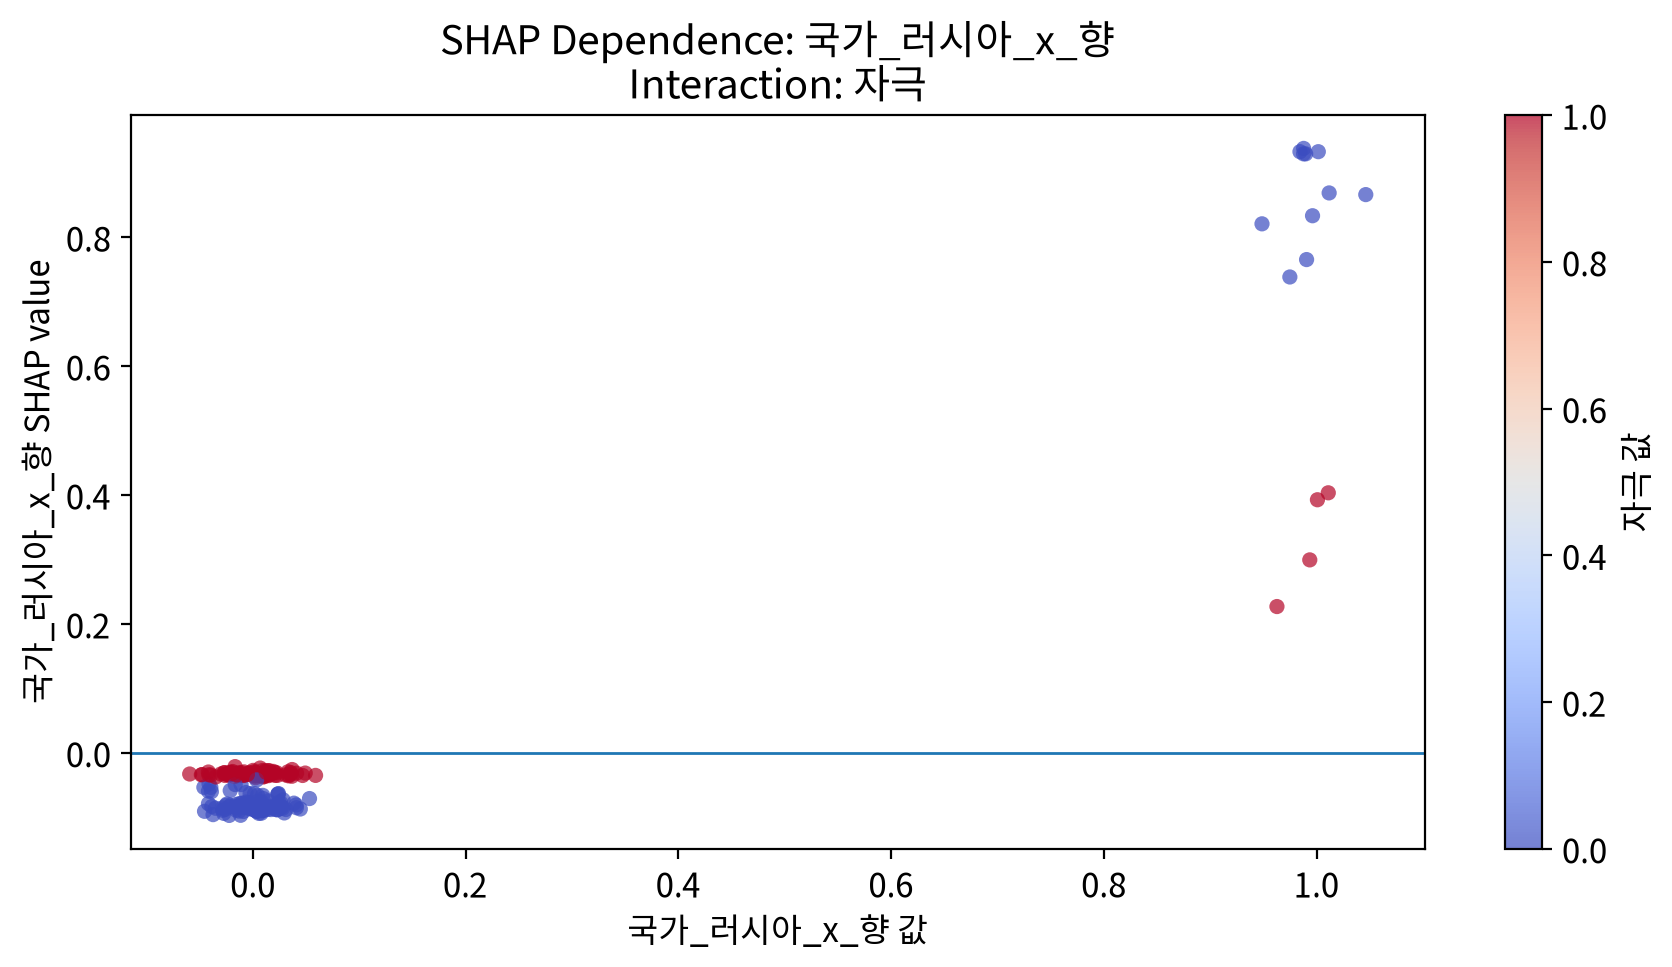

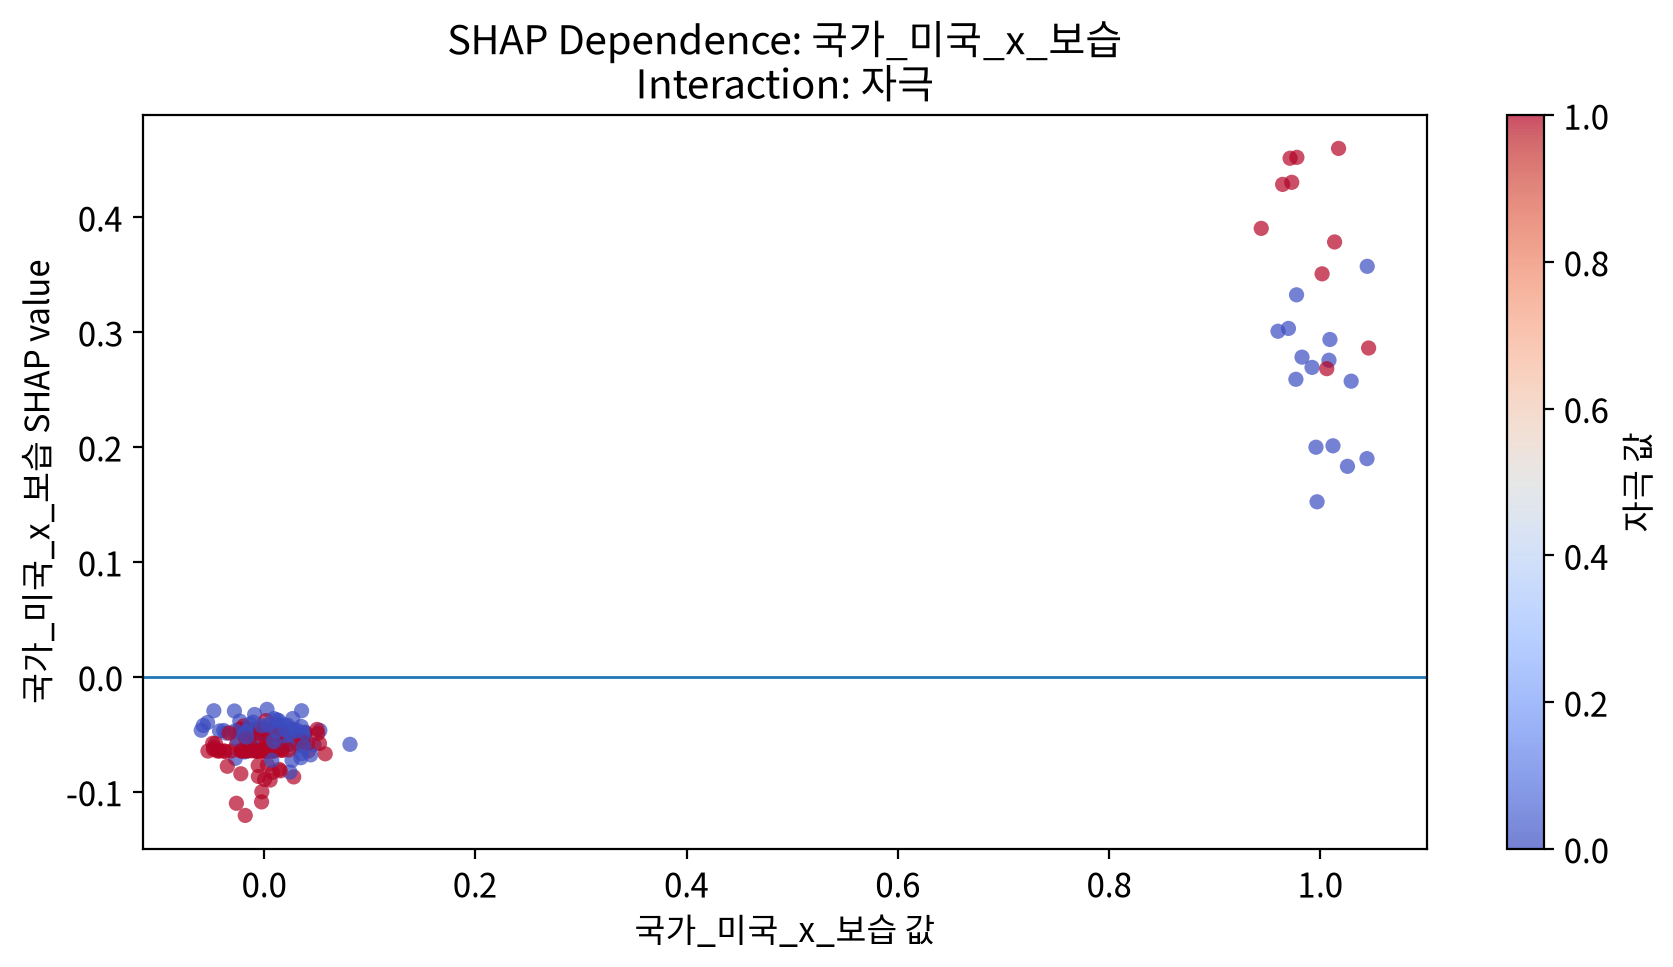

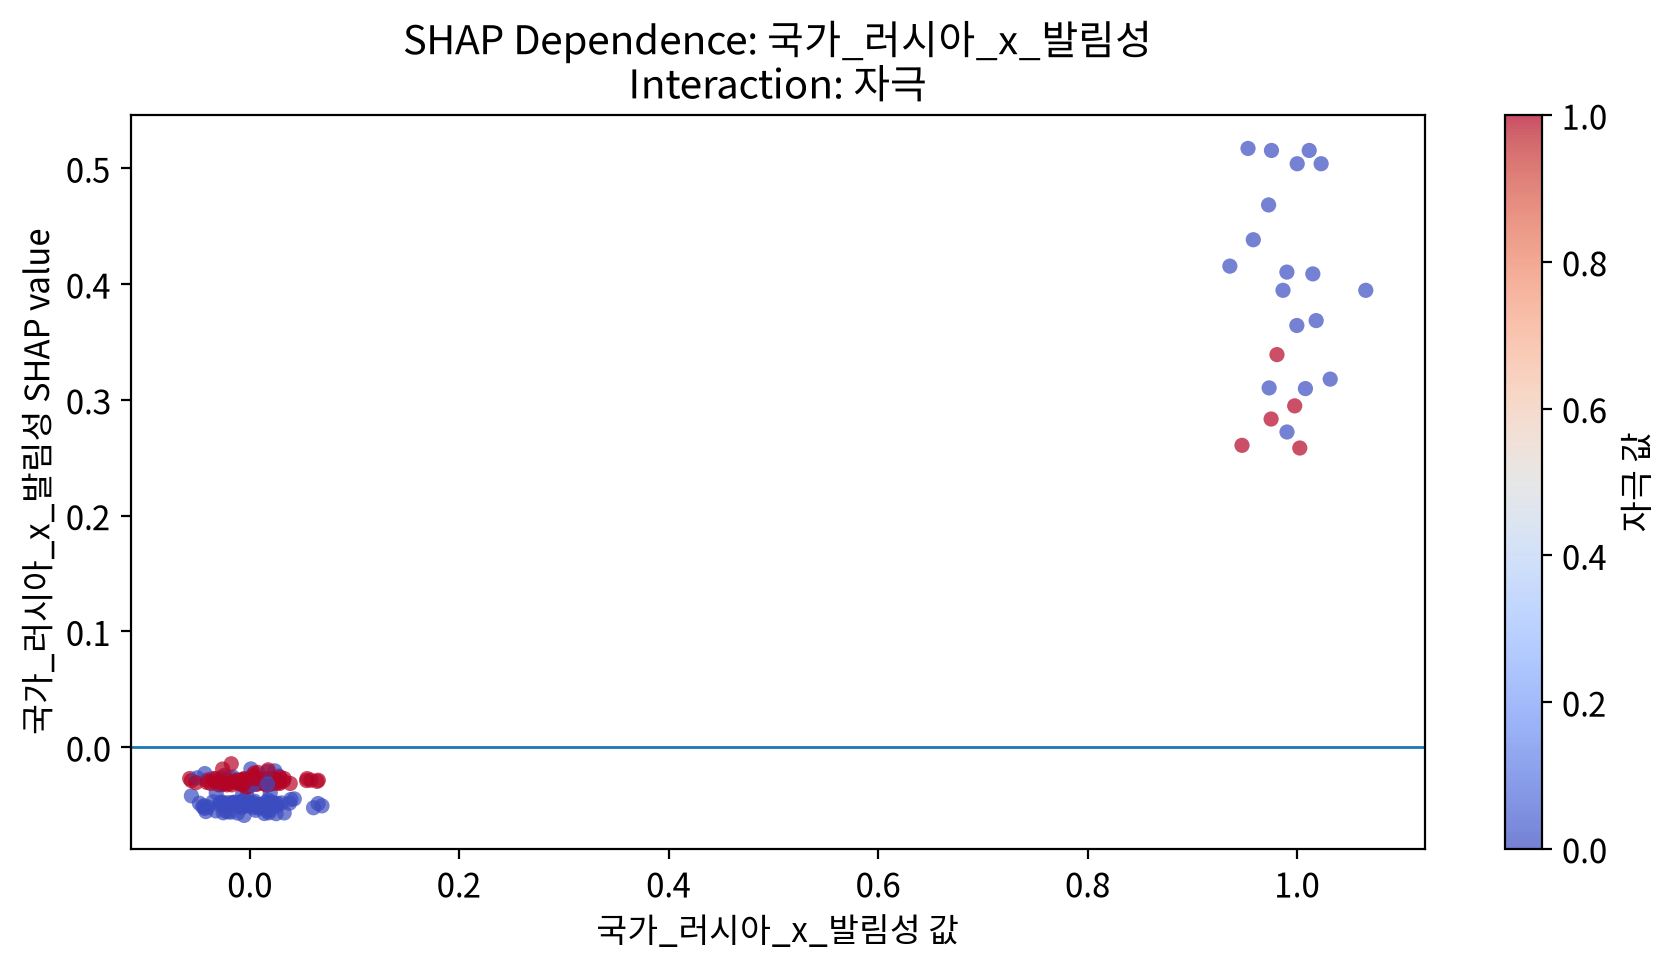

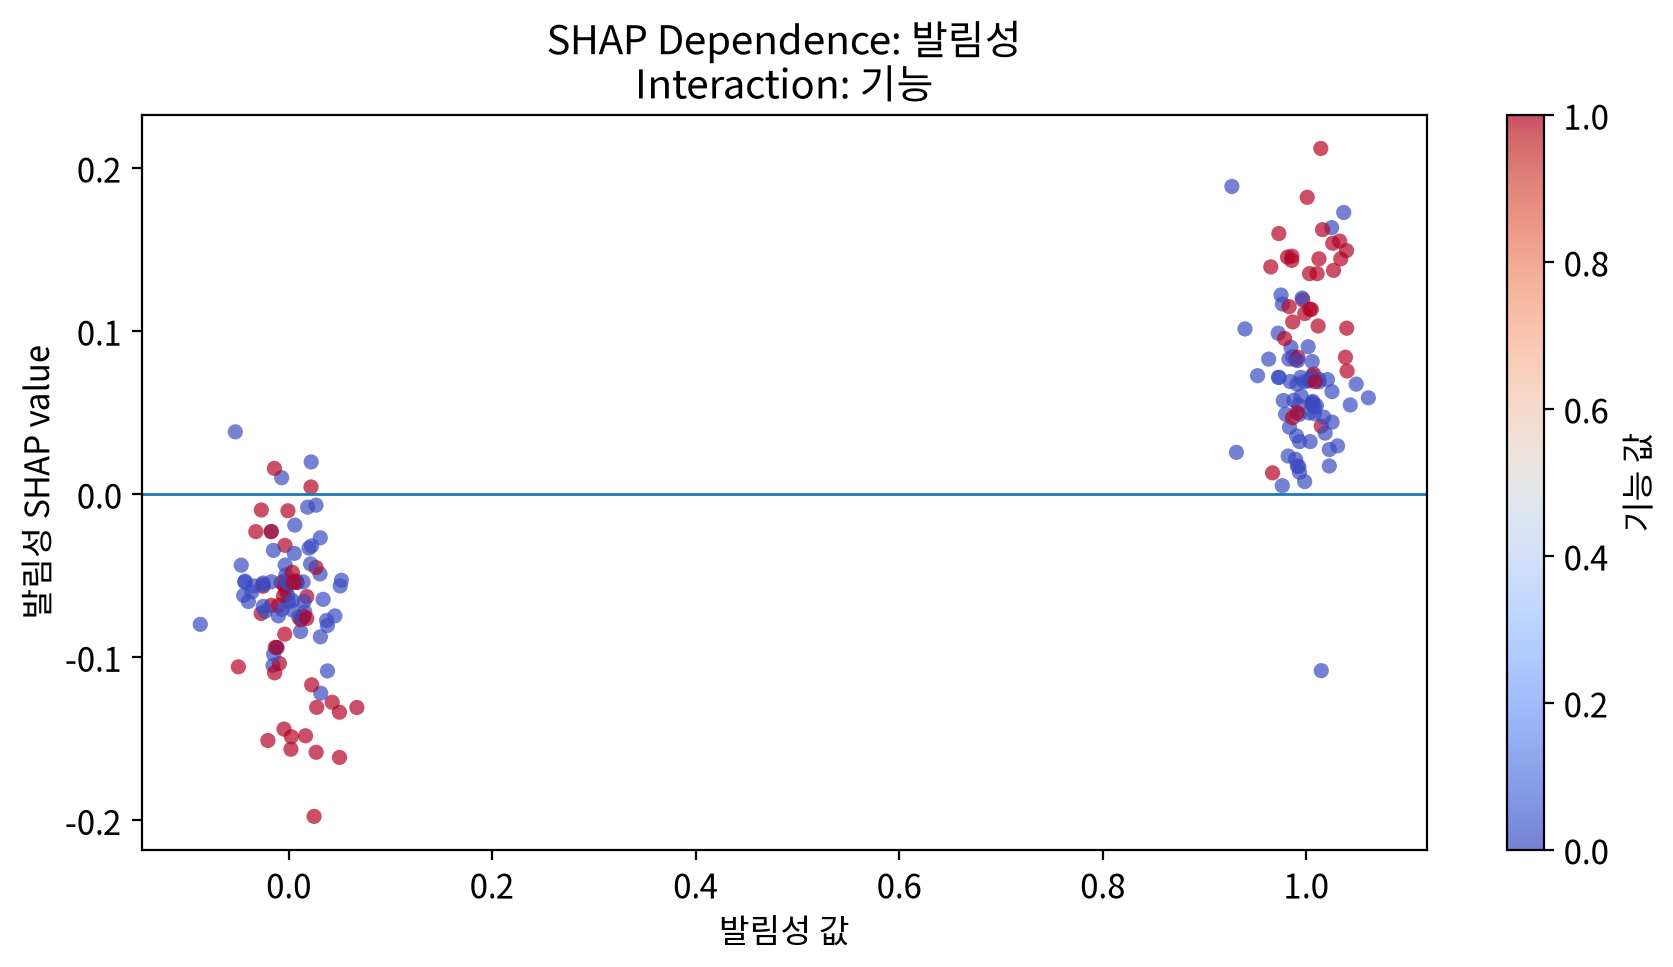

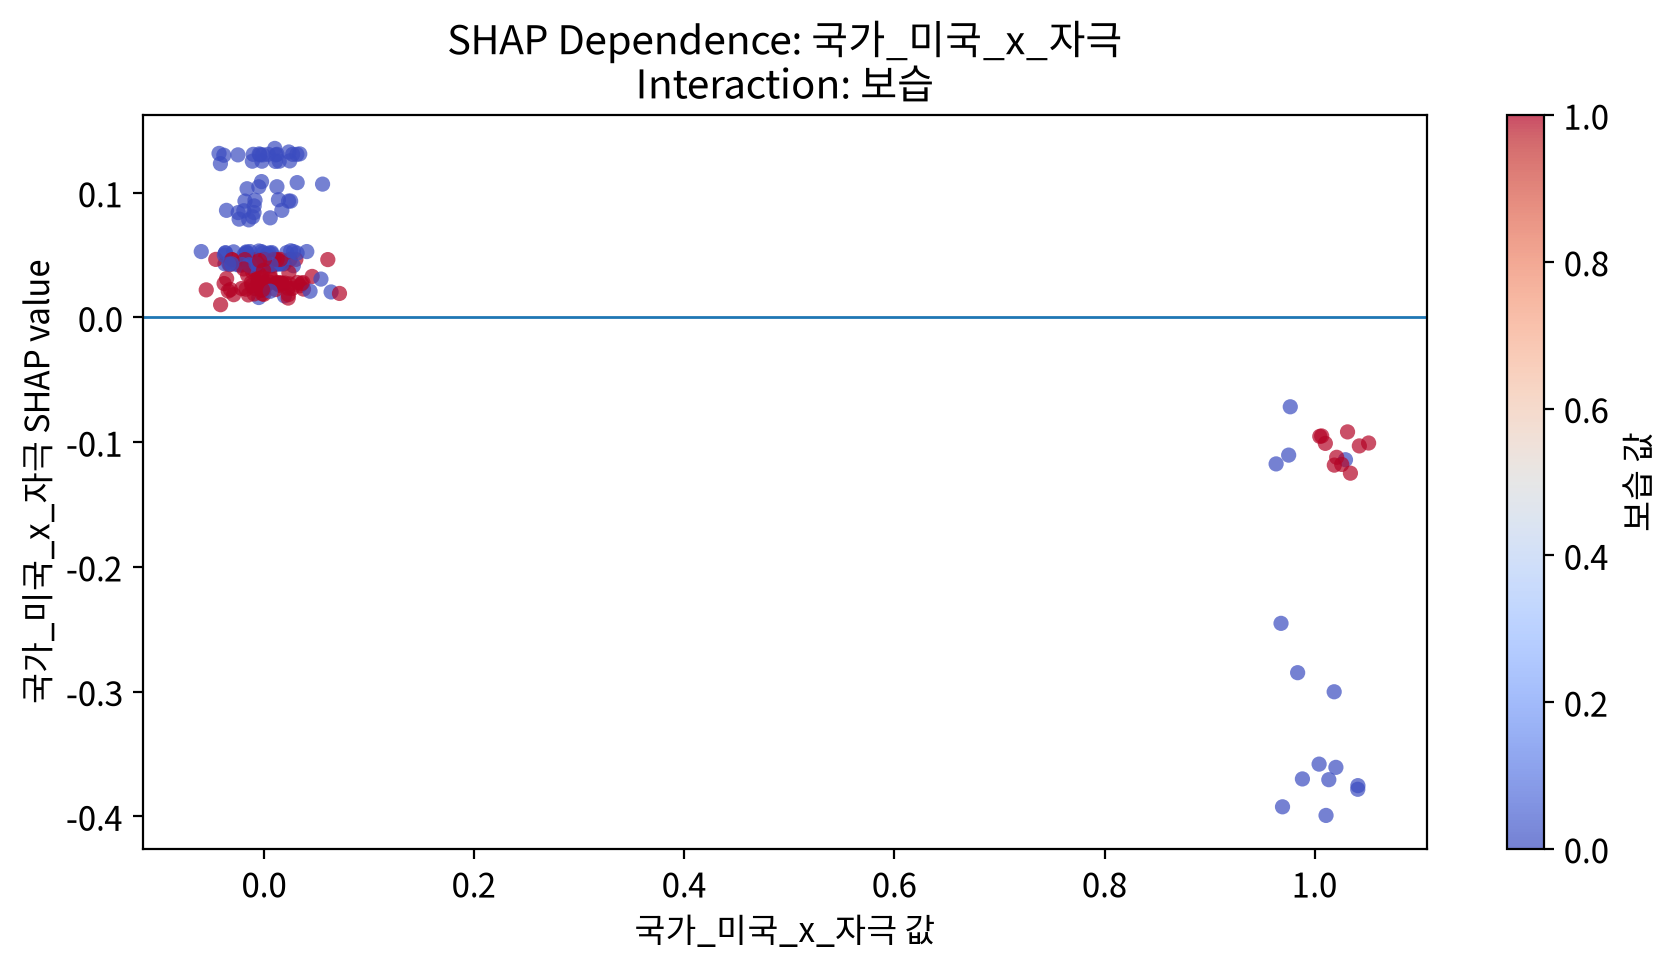

,feature,interaction_feature,mean_abs_interaction
0,자극,기능,0.078991
1,기능,자극,0.078991
2,보습,자극,0.033034
3,배송,자극,0.029119
4,국가_일본_x_보습,자극,0.019537
5,국가_러시아_x_향,자극,0.037791
6,국가_미국_x_보습,자극,0.009304
7,국가_러시아_x_발림성,자극,0.015094
8,발림성,기능,0.019579
9,국가_미국_x_자극,보습,0.027581


In [60]:
# =========================================================
# 11-5. SHAP Dependence Plot
# XGBoost Native TreeSHAP Interaction 사용
# shap 패키지 사용 안 함
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

DEP_TOP_K = min(10, len(non_product_rank))
dep_features = non_product_rank[:DEP_TOP_K]

# ---------------------------------------------------------
# 기존 SHAP 결과에서 데이터 가져오기
# ---------------------------------------------------------

raw_values = np.asarray(
    shap_result.attrs["shap_values"]
)

raw_data = shap_result.attrs["data"]

raw_features = list(
    shap_result.attrs["feature_names"]
)

# ---------------------------------------------------------
# XGBoost 모델 다시 가져오기
# ---------------------------------------------------------

final_model = my_ml.load_model(
    final_dir / f"{FINAL_MODEL_KEY}.pkl"
)

base_pipe = getattr(
    final_model,
    "best_estimator_",
    final_model
)

xgb_model = base_pipe.named_steps["model"]
booster = xgb_model.get_booster()

# SHAP 분석에 사용한 변환 데이터
X_native = raw_data.copy()

dmat_interaction = xgb.DMatrix(
    X_native
)

# ---------------------------------------------------------
# XGBoost Native SHAP Interaction 계산
#
# shape:
# (샘플수, 변수수+1, 변수수+1)
# 마지막 행/열은 bias
# ---------------------------------------------------------

interaction_values = booster.predict(
    dmat_interaction,
    pred_interactions=True
)

# bias 제거
interaction_values = interaction_values[
    :, :-1, :-1
]

print(
    "SHAP interaction shape:",
    interaction_values.shape
)

# ---------------------------------------------------------
# 제품_ID 관련 변수 제외
# ---------------------------------------------------------

usable_features = [
    f
    for f in raw_features
    if not (
        f == "제품_ID"
        or f.startswith("제품_ID_")
    )
]

# ---------------------------------------------------------
# 각 변수별 가장 강한 상호작용 상대 찾기
# ---------------------------------------------------------

pair_rows = []

for feature in dep_features:

    j = raw_features.index(feature)

    best_partner = None
    best_strength = -1

    for partner in usable_features:

        if partner == feature:
            continue

        k = raw_features.index(partner)

        strength = np.mean(
            np.abs(
                interaction_values[:, j, k]
            )
        )

        if strength > best_strength:
            best_strength = strength
            best_partner = partner

    pair_rows.append({
        "feature": feature,
        "interaction_feature": best_partner,
        "mean_abs_interaction": best_strength
    })

pairs = pd.DataFrame(pair_rows)

display(pairs)

# ---------------------------------------------------------
# Dependence Plot
#
# X축 = 해당 변수값
# Y축 = 해당 변수 SHAP 값
# 색상 = 가장 강한 상호작용 변수값
# ---------------------------------------------------------

rng = np.random.default_rng(
    RANDOM_STATE
)

for _, row in pairs.iterrows():

    feature = row["feature"]
    partner = row["interaction_feature"]

    j = raw_features.index(feature)
    k = raw_features.index(partner)

    x_value = (
        raw_data.iloc[:, j]
        .astype(float)
        .to_numpy()
    )

    color_value = (
        raw_data.iloc[:, k]
        .astype(float)
        .to_numpy()
    )

    shap_value = raw_values[:, j]

    # 0/1 값이 겹쳐 보이지 않도록 x축에만 작은 jitter
    if np.unique(x_value).size <= 2:
        x_plot = (
            x_value
            + rng.normal(
                0,
                0.025,
                size=len(x_value)
            )
        )
    else:
        x_plot = x_value

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    scatter = ax.scatter(
        x_plot,
        shap_value,
        c=color_value,
        cmap="coolwarm",
        s=30,
        alpha=0.70,
        edgecolors="none"
    )

    ax.axhline(
        0,
        linewidth=1
    )

    ax.set_xlabel(
        f"{feature} 값"
    )

    ax.set_ylabel(
        f"{feature} SHAP value"
    )

    ax.set_title(
        f"SHAP Dependence: {feature}\n"
        f"Interaction: {partner}"
    )

    cbar = plt.colorbar(
        scatter,
        ax=ax
    )

    cbar.set_label(
        f"{partner} 값"
    )

    plt.tight_layout()
    plt.show()

pairs

## 11-6. Local SHAP — 제품 ID 통합

기존 Waterfall은 모델공간 기준이라 `제품_ID_*`가 다시 나뉠 수 있습니다.

아래에서는 제품 ID를 합친 **원본 변수 단위 Local SHAP 기여도**를 대표 관측치 5개에서 확인합니다.


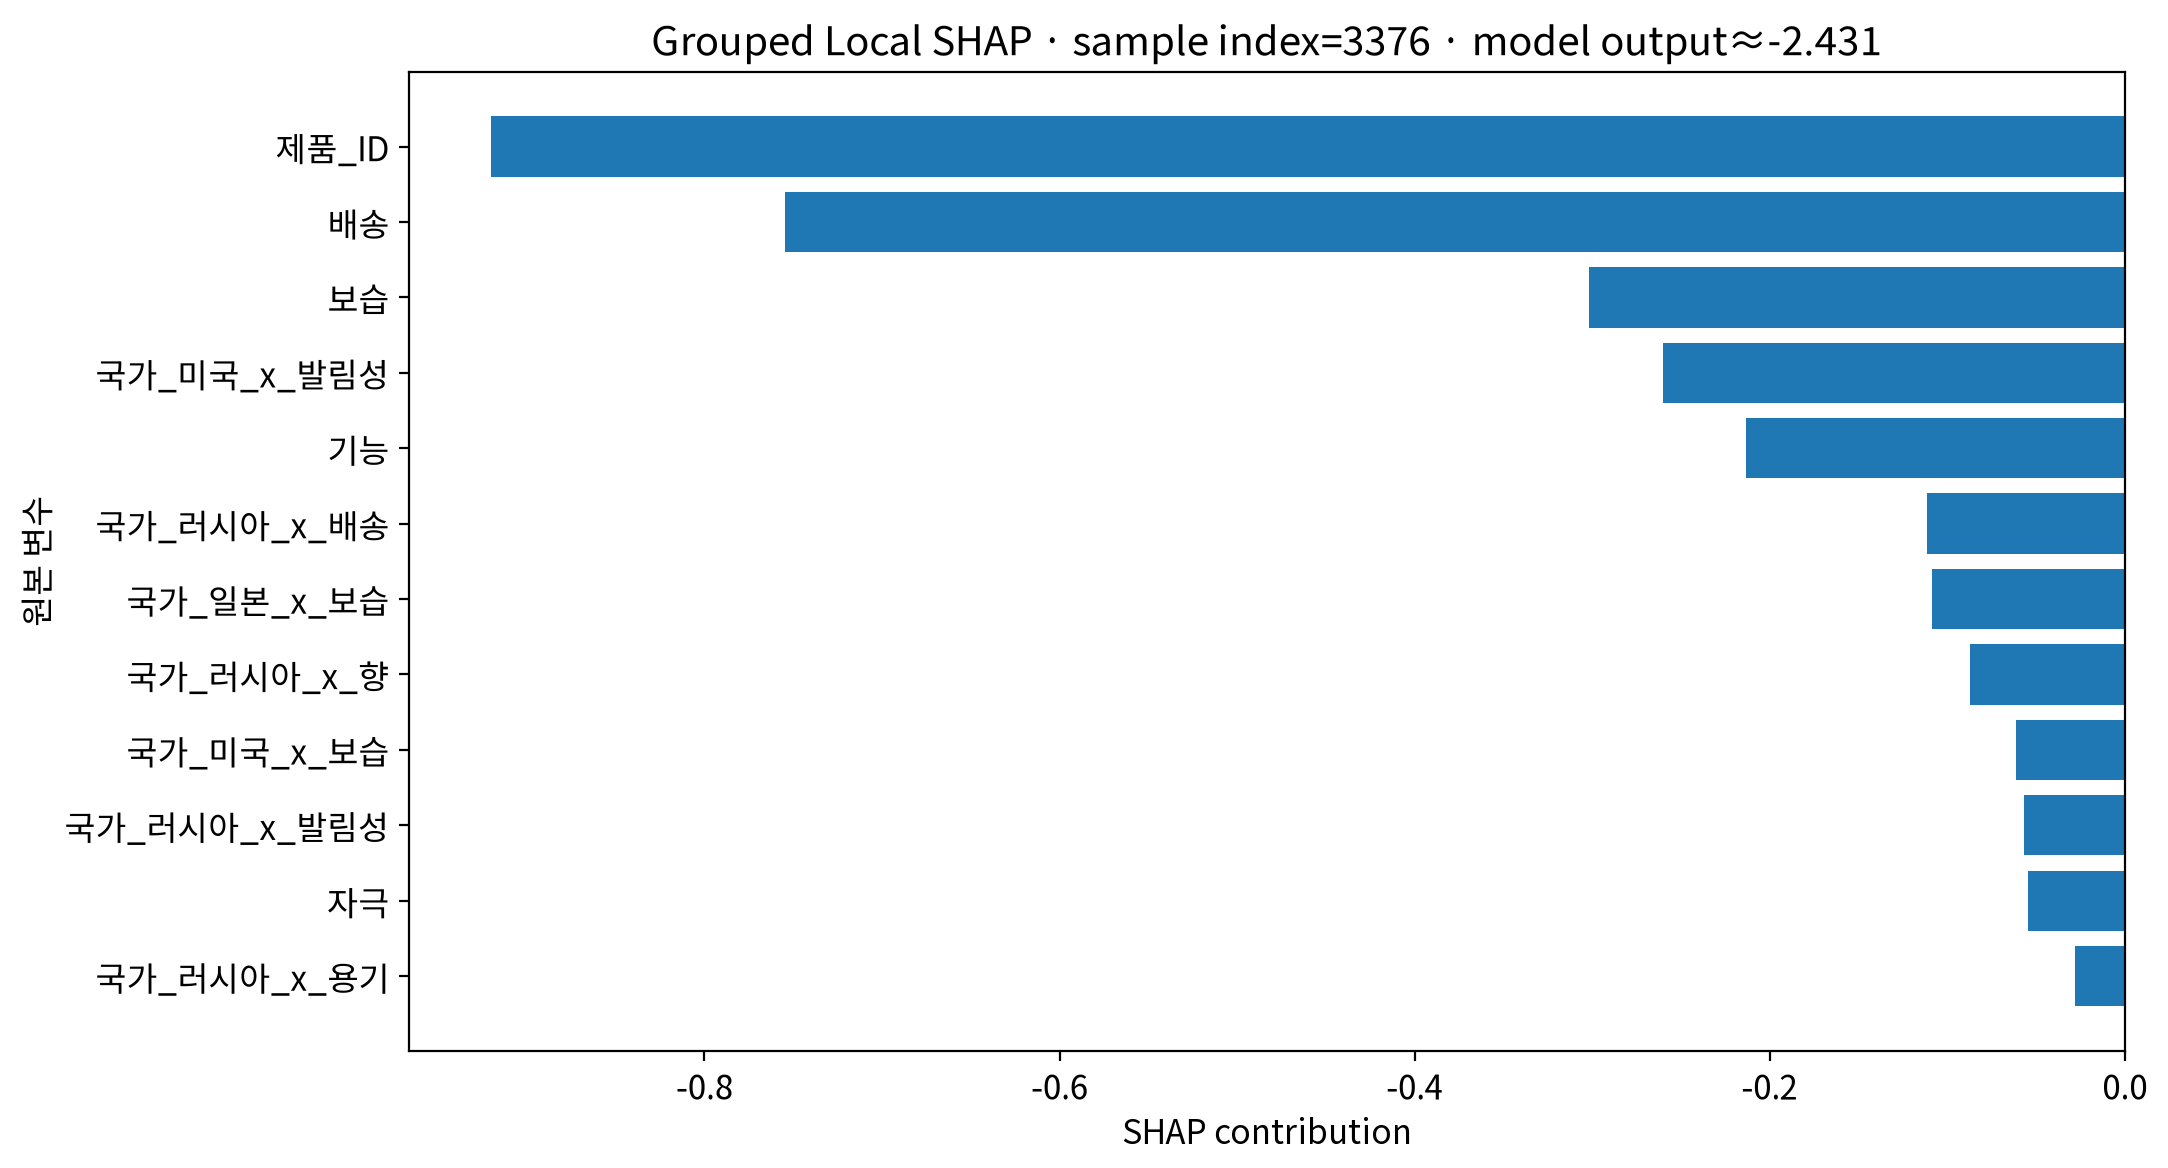

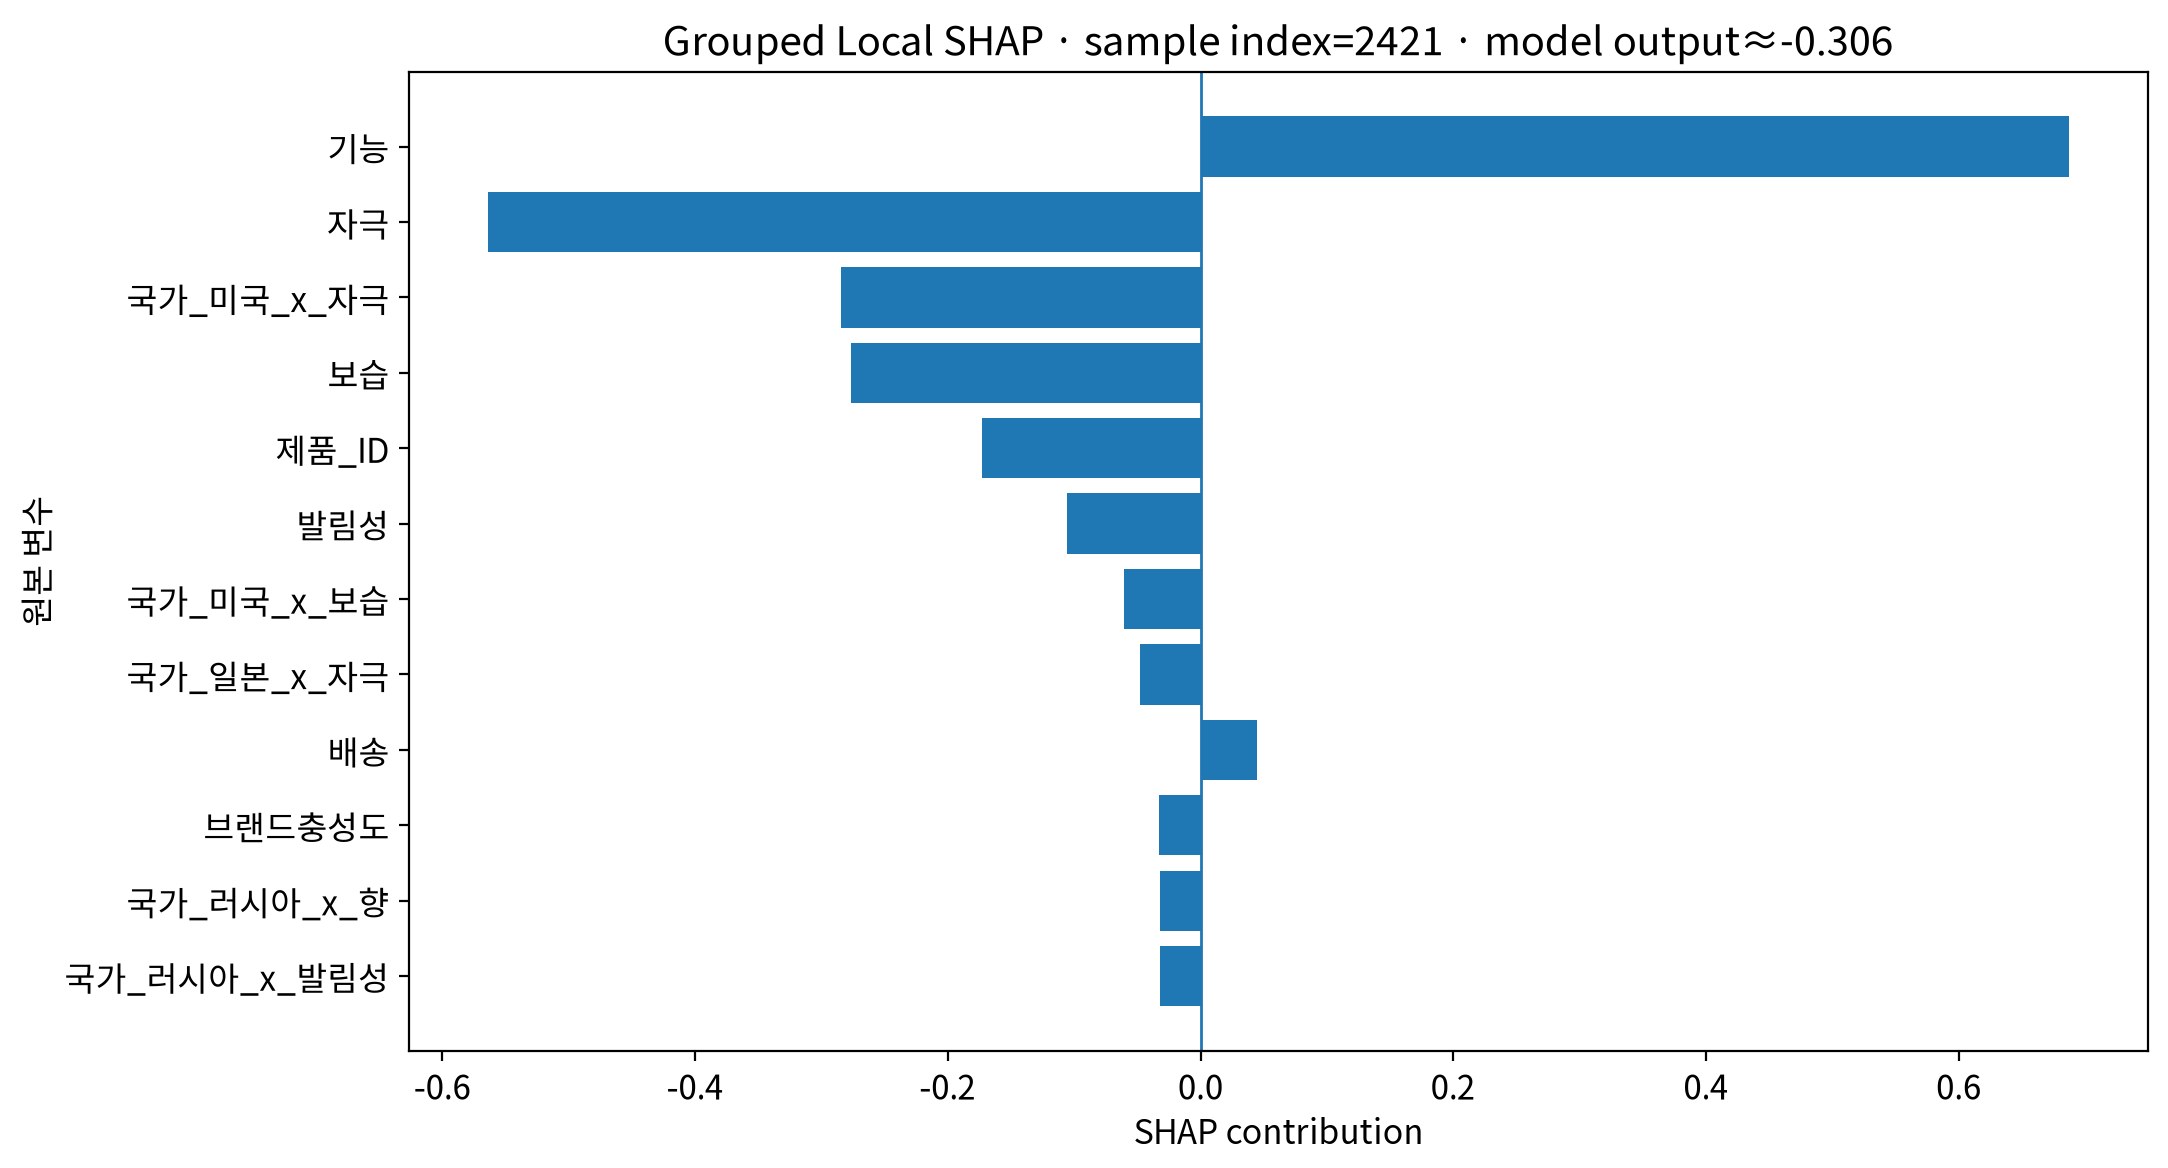

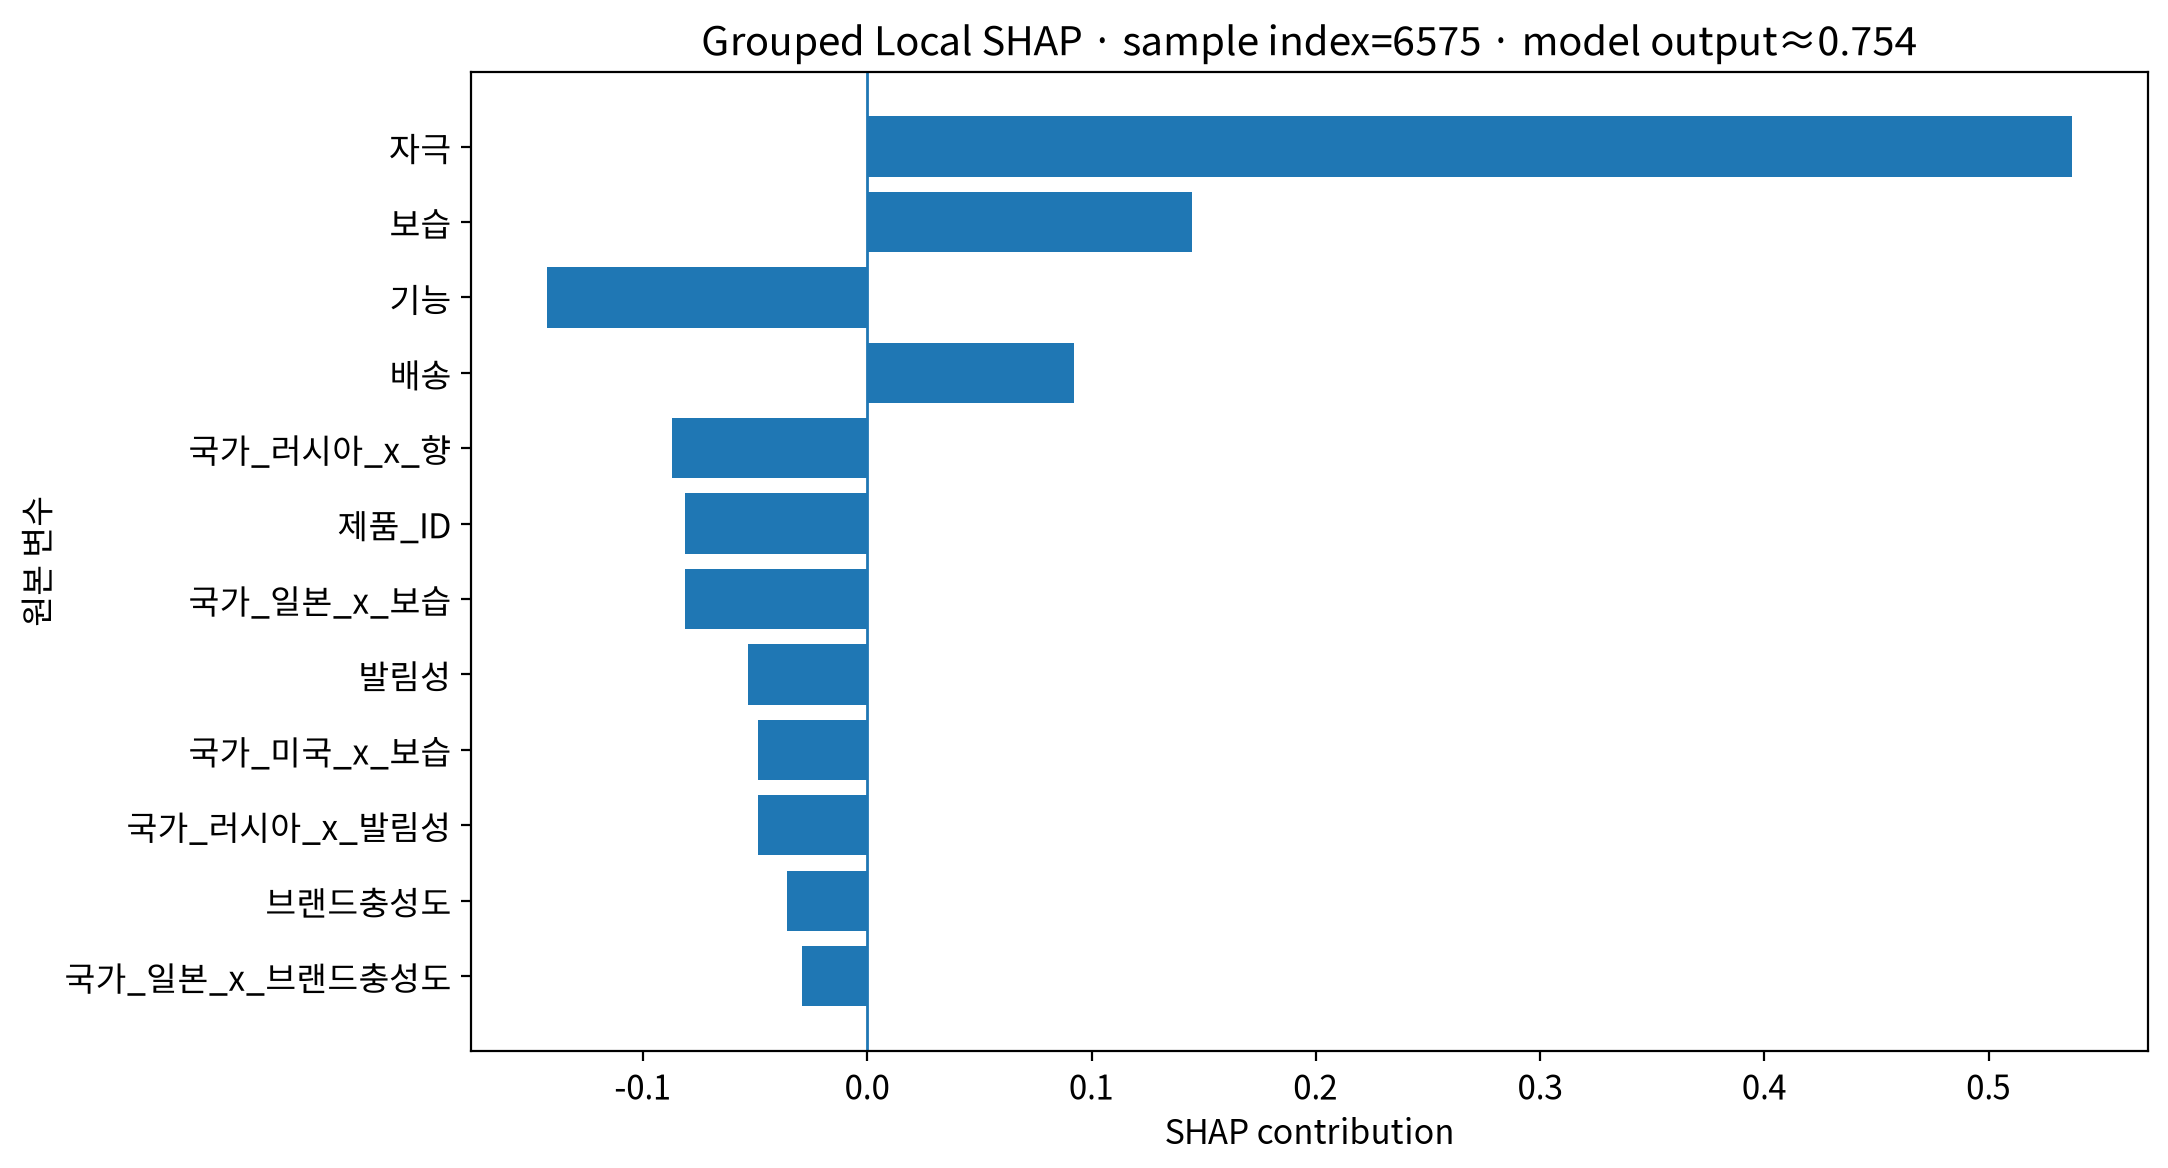

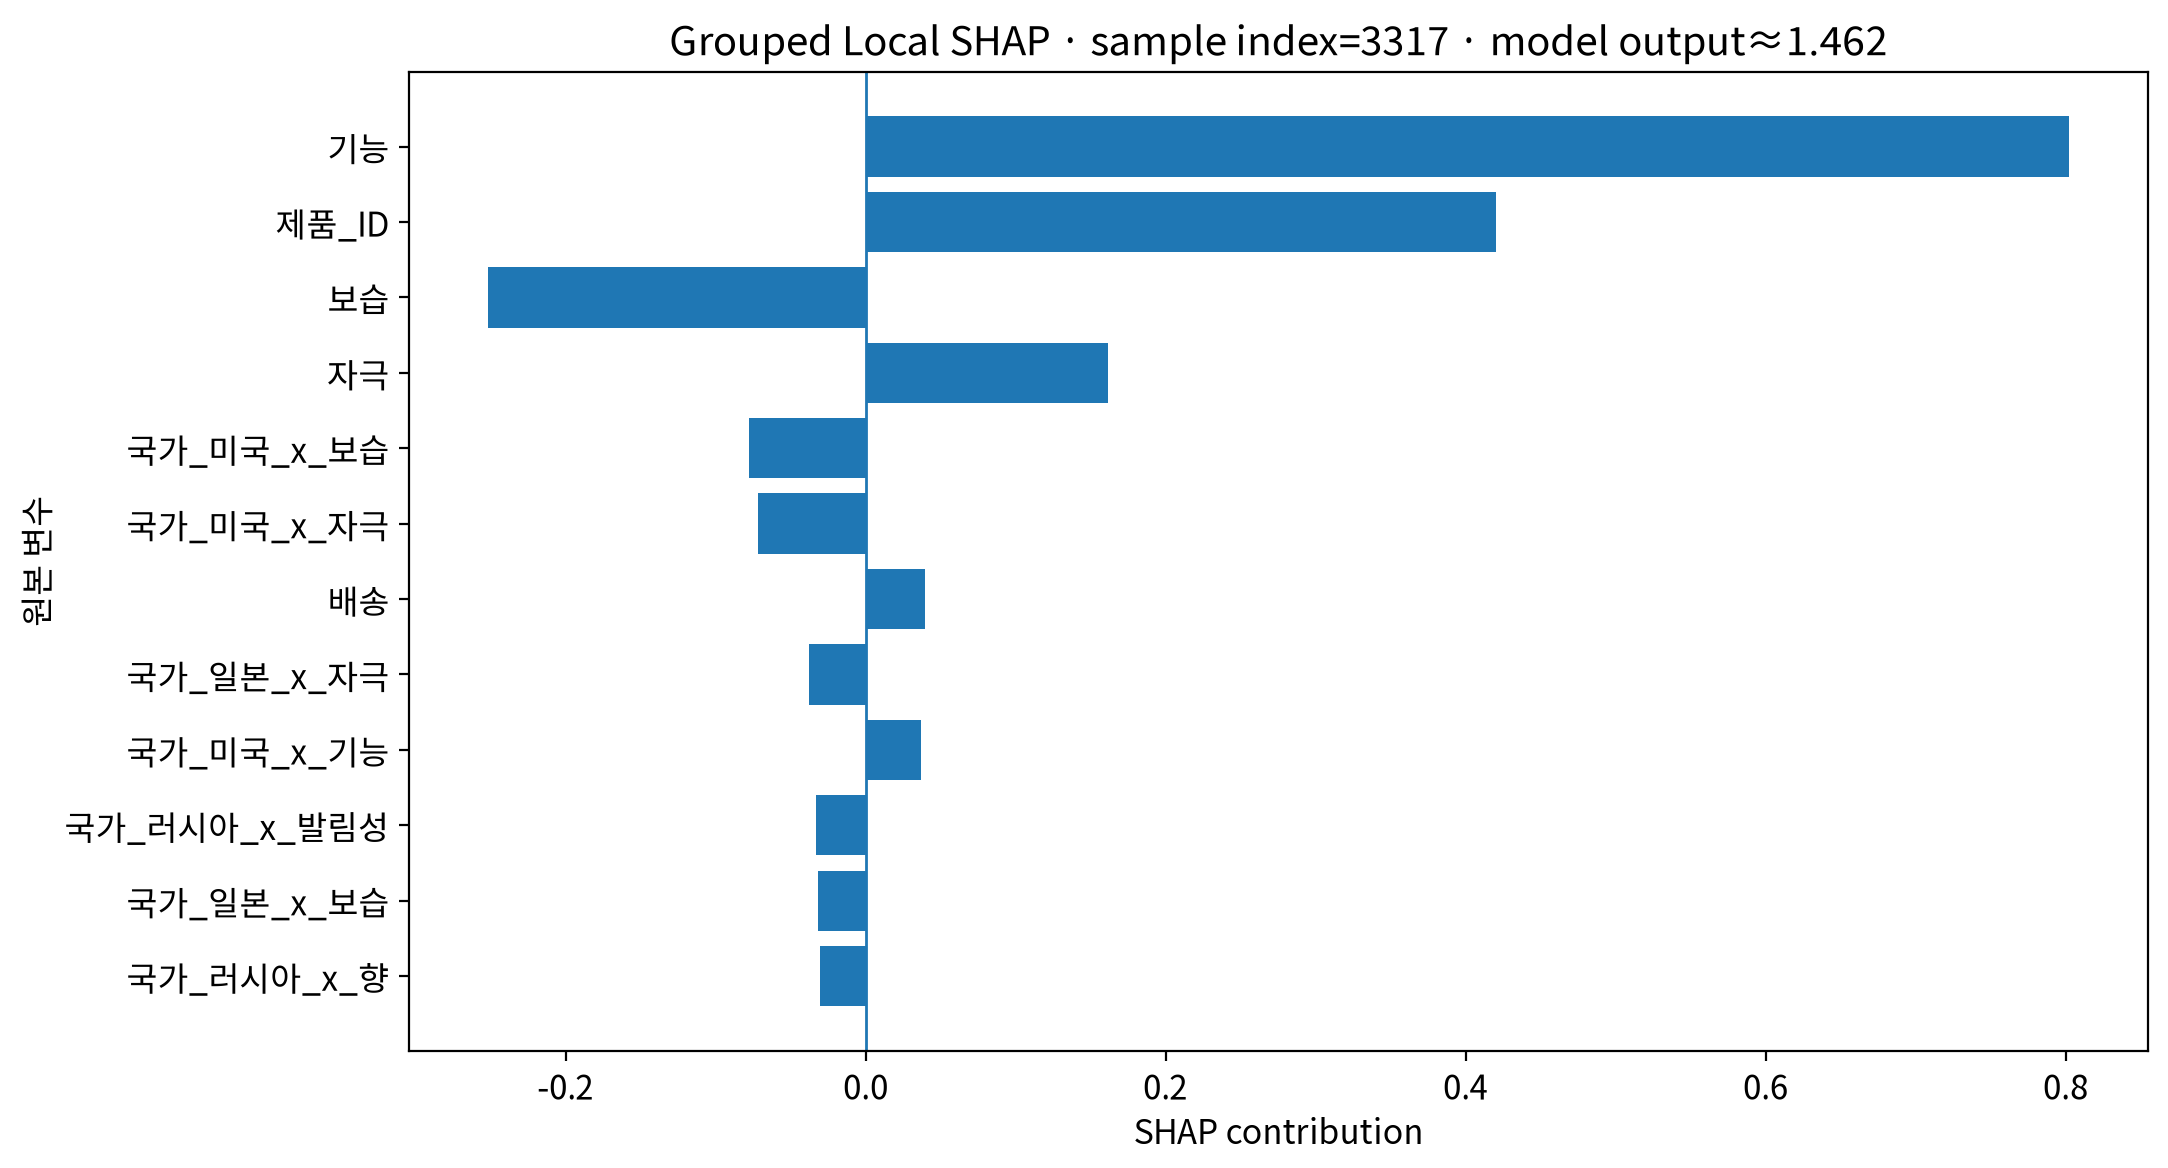

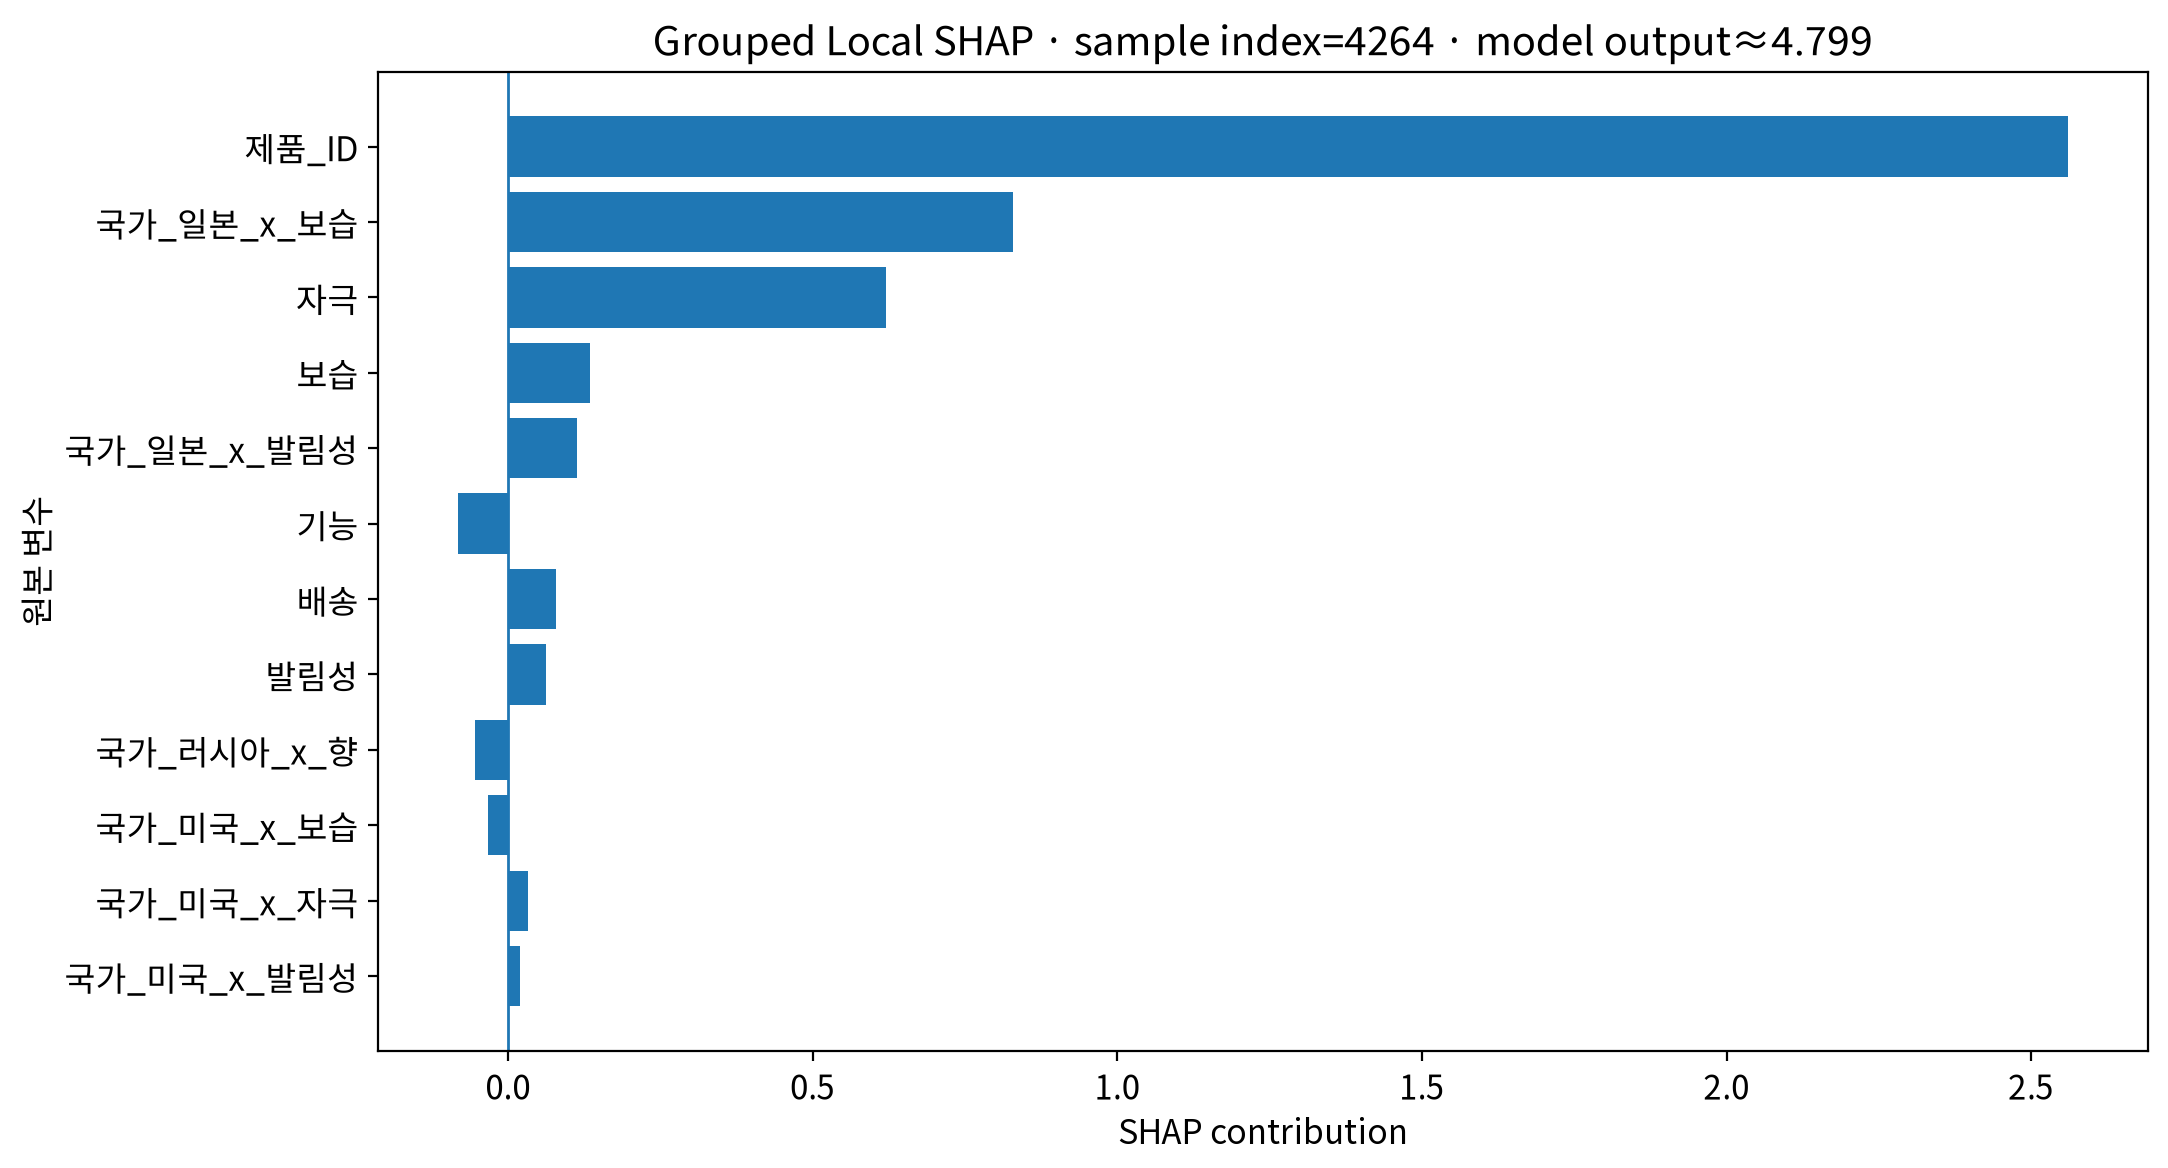

In [61]:
grouped_values = shap_grouped.attrs["grouped_shap_values"]
grouped_df = shap_grouped.attrs["grouped_shap_df"]

base_value = shap_grouped.attrs["expected_value"]
base_value = float(np.asarray(base_value).reshape(-1)[0])

pred_output = base_value + grouped_values.sum(axis=1)

order = np.argsort(pred_output)
positions = np.unique(
    np.round(np.linspace(0, len(order) - 1, 5)).astype(int)
)
picked = order[positions]

for pos in picked:
    row_shap = grouped_df.iloc[pos].copy()
    row_shap = row_shap.reindex(
        row_shap.abs().sort_values(ascending=False).index
    ).head(12)

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(np.arange(len(row_shap)), row_shap.values)
    ax.set_yticks(np.arange(len(row_shap)))
    ax.set_yticklabels(row_shap.index)
    ax.invert_yaxis()
    ax.axvline(0, linewidth=1)

    original_index = grouped_df.index[pos]

    ax.set_title(
        f"Grouped Local SHAP · sample index={original_index} "
        f"· model output≈{pred_output[pos]:.3f}"
    )
    ax.set_xlabel("SHAP contribution")
    ax.set_ylabel("원본 변수")

    plt.tight_layout()
    plt.show()


## 11-7. SHAP 해석 주의

- SHAP은 **통계적 유의성(p-value)**이 아니다.
- SHAP은 **인과효과**가 아니라 모델 예측에 대한 기여도이다.
- Global Bar의 `제품_ID`는 특정 제품 하나가 아니라 **제품 자체 차이 전체의 예측 기여도**이다.
- `제품_ID`는 여러 제품 범주의 통합값이므로 **증가/감소 방향은 해석하지 않는다.**
- 9개 속성과 국가×속성의 방향은 Beeswarm과 Dependence Plot을 함께 보고 판단한다.


# 12. 최종 보고서 정리용

## 데이터 설계

```text
표본: 6,813건
Y: 만족(1) / 불만족(0)

제품_순위:
- 로지스틱/ML에서 순위형 변수로 사용하지 않음
- 국가마다 동일 순위가 서로 다른 제품을 의미
- 제품_ID(KR_P01 ~ RU_P10)로 변환하여 명목형 통제

입력 변수:
제품_ID 1개
+ 9개 속성
+ 국가×속성 27개
= 총 37개
```

## 모델 선택 절차

```text
Train 70% / Test 30%
        ↓
Train 내부 5-Fold CV
        ↓
11개 모델 베이스라인 탐색
        ↓
사전에 정한 8개 후보 모델 튜닝
        ↓
CV 평균 F1 기준 최종 모델 선택
        ↓
Train-CV 과적합 진단
        ↓
최종 모델/변수 구성 확정
        ↓
Test set 최초 1회 평가
        ↓
Feature Importance / SHAP 해석
```

## Test set 오염 방지 설명

> 모델 비교와 하이퍼파라미터 튜닝, 최종 모델 선택은 모두 Train 데이터 내부의 5-Fold Cross Validation 결과를 기준으로 수행하였다. Test set은 모델 및 하이퍼파라미터가 모두 확정된 이후 최종 일반화 성능을 평가하기 위해 한 번만 사용하였다. 따라서 Test 성능을 기준으로 모델을 선택함으로써 발생할 수 있는 평가 편향을 방지하였다.

## 해석 목적

이 프로젝트는 극단 평점 중심으로 구성한 연구 표본을 사용하므로  
실제 서비스 전체 모집단의 절대적인 예측 성능보다 **만족/불만족을 구분하는 요인과 국가별 차이를 설명하는 목적**으로 해석합니다.


## SHAP `제품_ID` 통합 설명

> `제품_ID`는 제품 자체의 차이를 통제하기 위한 명목형 변수이며 One-Hot Encoding 과정에서 여러 제품 더미로 변환된다. SHAP은 모델이 실제 학습한 변환 후 피처공간에서 계산되므로 개별 제품 더미가 각각 나타난다. 본 분석에서는 동일 원본 변수에 속하는 `제품_ID_*` SHAP 값을 **관측치별로 먼저 합산한 뒤 mean(|SHAP|)을 계산**하여 `제품_ID` 하나의 전역 중요도로 제시하였다. 이를 통해 개별 제품 더미의 나열이 아니라 **제품 자체 차이의 전체 예측 기여도**를 해석하였다.
